# 🚇 Data Mining aplicado aos Atrasos do Metrô de Toronto (TTC Subway Delay Data)

**Projeto acadêmico de Data Mining — Metodologia KDD (Knowledge Discovery in Databases)**

---

## Sumário

0. [Contexto, objetivos e perguntas de pesquisa](#0.-Contexto,-objetivos-e-perguntas-de-pesquisa)
1. [Data Selection — Seleção de Dados](#1.-Data-Selection-—-Seleção-de-Dados)
2. [Data Preprocessing — Pré-processamento & Limpeza](#2.-Data-Preprocessing-—-Pré-processamento-&-Limpeza)
3. [Data Transformation — Transformação & Feature Engineering](#3.-Data-Transformation-—-Transformação-&-Feature-Engineering)
4. [Data Mining — Mineração e Análise de Padrões](#4.-Data-Mining-—-Mineração-e-Análise-de-Padrões)
5. [Evaluation & Interpretation — Visualização & Insights](#5.-Evaluation-&-Interpretation-—-Visualização-&-Insights)
6. [Conclusões e respostas às perguntas de pesquisa](#6.-Conclusões-e-respostas-às-perguntas-de-pesquisa)

## 0. Contexto, objetivos e perguntas de pesquisa

A **Toronto Transit Commission (TTC)** publica no Portal de Dados Abertos de Toronto o registro de cada incidente que
interrompe ou degrada o serviço do metrô. Cada linha do dataset representa **um incidente**, com data/hora, estação,
código da causa, minutos de atraso provocados (`Min Delay`) e o intervalo até o próximo trem (`Min Gap`).

### O processo KDD

O KDD (Fayyad, Piatetsky-Shapiro & Smyth, 1996) organiza a descoberta de conhecimento em etapas encadeadas:

| Etapa | Pergunta que responde | Neste notebook |
|---|---|---|
| **1. Selection** | Quais dados são relevantes? | Carga, inspeção e recorte das linhas YU, BD e SHP |
| **2. Preprocessing** | Os dados são confiáveis? | Nulos, ruído em `Line`/`Station`, datas e outliers |
| **3. Transformation** | Os dados estão na forma certa para minerar? | `Hour`, `Is_Rush_Hour`, categorias de incidente, nomes de linha |
| **4. Data Mining** | Que padrões existem? | Agregações, rankings, comparações e matriz temporal |
| **5. Evaluation** | O que os padrões significam? | Visualizações e insights executivos |

### Dicionário de dados original

| Coluna | Descrição |
|---|---|
| `_id` | Identificador sequencial do registro |
| `Date` | Data do incidente (`YYYY-MM-DD`) |
| `Time` | Hora do incidente (`HH:MM`, 24h) |
| `Day` | Dia da semana |
| `Station` | Estação (ou trecho) onde o incidente ocorreu — texto livre |
| `Code` | Código TTC da causa do atraso |
| `Min Delay` | Minutos de atraso causados ao serviço |
| `Min Gap` | Minutos de intervalo entre o trem afetado e o seguinte |
| `Bound` | Sentido do trem (`N`, `S`, `E`, `W`, `B`) |
| `Line` | Linha do metrô (`YU`, `BD`, `SHP`) — texto livre |
| `Vehicle` | Número do trem/veículo (`0` = não informado) |

### Perguntas de pesquisa

1. **Volume e motivos:** quais as principais categorias de causa e a frequência de cada uma?
2. **Padrões temporais:** como os atrasos se distribuem por dia da semana e por hora? O pico (rush) é mais vulnerável?
   Como fica a matriz *Dia da Semana × Hora*?
3. **Linhas e estações:** quais linhas acumulam mais minutos e ocorrências? Quais as 10 estações mais críticas?
4. **Impacto no passageiro:** qual o `Min Delay` e o `Min Gap` médios por ocorrência? Qual o impacto acumulado por categoria?

### 0.1 Configuração do ambiente

Todas as bibliotecas são importadas no topo e a identidade visual dos gráficos é definida uma única vez
(estilo limpo, fundo claro, títulos em negrito e cores oficiais das linhas da TTC).

In [1]:
from datetime import time
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "savefig.bbox": "tight",
})

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


In [2]:
DATA_FILE = "TTC Subway Delay Data since 2025.csv"

LINES_IN_SCOPE = {"YU": "Yonge-University", "BD": "Bloor-Danforth", "SHP": "Sheppard"}
MULTI_LINE_LABEL = "Multi-linha"

LINE_COLORS = {                      # cores oficiais da sinalização TTC
    "Yonge-University": "#F8C300",
    "Bloor-Danforth": "#00923F",
    "Sheppard": "#A21A68",
    MULTI_LINE_LABEL: "#8C8C8C",
}

RUSH_HOUR_WINDOWS = [(time(7, 0), time(9, 0)), (time(16, 0), time(18, 0))]   # intervalos [início, fim)

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
WEEKDAY_PT = {
    "Monday": "Segunda", "Tuesday": "Terça", "Wednesday": "Quarta", "Thursday": "Quinta",
    "Friday": "Sexta", "Saturday": "Sábado", "Sunday": "Domingo",
}


def resolve_data_path(filename: str = DATA_FILE) -> Path:
    # Procura o CSV nos locais mais comuns para o notebook rodar a partir da raiz do projeto ou de subpastas.
    candidates = [Path(filename), Path("src") / filename, Path("..") / "src" / filename, Path("data") / filename]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"'{filename}' não encontrado. Locais verificados: {[str(c) for c in candidates]}")


DATA_PATH = resolve_data_path()
print(f"Arquivo de dados: {DATA_PATH.resolve()}")

Arquivo de dados: /Users/rafael.romano/dev/rafaelromwno/ttc-toronto/src/TTC Subway Delay Data since 2025.csv


In [3]:
def format_thousands(ax, axis: str = "x") -> None:
    # Formata os ticks de um eixo com separador de milhar.
    formatter = mticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(formatter)


def label_bars(ax, fmt: str = "{:,.0f}", padding: int = 3, fontsize: int = 10) -> None:
    # Escreve o valor de cada barra ao lado/acima dela.
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues],
                     padding=padding, fontsize=fontsize)


def style_axis(ax, title: str, xlabel: str = "", ylabel: str = "", subtitle: str | None = None) -> None:
    # Aplica título, subtítulo e rótulos de eixo de forma padronizada.
    ax.set_title(title, loc="left", pad=28 if subtitle else None)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def pct(value: float, digits: int = 1) -> str:
    return f"{value:.{digits}%}"

---
## 1. Data Selection — Seleção de Dados

**Objetivo:** carregar o dataset bruto, entender sua estrutura (dimensões, tipos, cardinalidade, nulos) e recortar
apenas os registros pertinentes ao problema: incidentes das três linhas de metrô pesado operadas pela TTC —
**YU** (Linha 1, Yonge-University), **BD** (Linha 2, Bloor-Danforth) e **SHP** (Linha 4, Sheppard).

### 1.1 Carga do dataset

In [4]:
def load_raw_data(path: Path) -> pd.DataFrame:
    # Lê o CSV preservando os valores originais; tipagem e limpeza ficam para o pré-processamento.
    return pd.read_csv(path)


raw_df = load_raw_data(DATA_PATH)
print(f"Dimensões (linhas, colunas): {raw_df.shape}")
raw_df.head(10)

Dimensões (linhas, colunas): (45475, 11)


,_id,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle
0,1,2025-01-01,02:10,Wednesday,BATHURST STATION,MUSAN,5,9,E,BD,5227
1,2,2025-01-01,02:30,Wednesday,DUNDAS STATION,MUIRS,0,0,NaN,YU,0
2,3,2025-01-01,02:32,Wednesday,BROADVIEW STATION,PUMST,0,0,E,BD,0
3,4,2025-01-01,02:58,Wednesday,KEELE STATION,EUSC,0,0,W,BD,5293
4,5,2025-01-01,02:58,Wednesday,COXWELL STATION,SUAE,0,0,NaN,BD,0
5,6,2025-01-01,07:59,Wednesday,DONLANDS STATION,TUNOA,5,10,W,BD,5000
6,7,2025-01-01,08:13,Wednesday,BLOOR STATION,PUTR,9,0,S,YU,5836
7,8,2025-01-01,08:15,Wednesday,BLOOR STATION,PUTR,5,0,N,YU,5706
8,9,2025-01-01,09:14,Wednesday,FINCH STATION,SUDP,0,0,S,YU,5596
9,10,2025-01-01,09:22,Wednesday,BATHURST STATION,SUUT,0,0,E,BD,5312


### 1.2 Inspeção estrutural: tipos, memória e nulos

In [5]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45475 entries, 0 to 45474
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   _id        45475 non-null  int64
 1   Date       45475 non-null  str  
 2   Time       45475 non-null  str  
 3   Day        45475 non-null  str  
 4   Station    45475 non-null  str  
 5   Code       45475 non-null  str  
 6   Min Delay  45475 non-null  int64
 7   Min Gap    45475 non-null  int64
 8   Bound      29615 non-null  str  
 9   Line       45298 non-null  str  
 10  Vehicle    45475 non-null  int64
dtypes: int64(4), str(7)
memory usage: 3.8 MB


In [6]:
def profile_columns(df: pd.DataFrame) -> pd.DataFrame:
    # Perfil por coluna: tipo, nulos, cardinalidade e um exemplo de valor.
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(2),
        "valores únicos": df.nunique(),
        "exemplo": df.iloc[0],
    })


profile_columns(raw_df)

,dtype,nulos,% nulos,valores únicos,exemplo
_id,int64,0,0.00,45475,1
Date,str,0,0.00,608,2025-01-01
Time,str,0,0.00,1437,02:10
Day,str,0,0.00,7,Wednesday
Station,str,0,0.00,1251,BATHURST STATION
Code,str,0,0.00,140,MUSAN
Min Delay,int64,0,0.00,135,5
Min Gap,int64,0,0.00,133,9
Bound,str,15860,34.88,5,E
Line,str,177,0.39,37,BD


In [7]:
print(f"Período coberto: {raw_df['Date'].min()} → {raw_df['Date'].max()}")
print(f"Linhas duplicadas (ignorando _id): {raw_df.drop(columns='_id').duplicated().sum()}")
print(f"_id único? {raw_df['_id'].is_unique}")
raw_df[["Min Delay", "Min Gap"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).T

Período coberto: 2025-01-01 → 2026-08-31
Linhas duplicadas (ignorando _id): 66
_id único? True


,count,mean,std,min,50%,75%,90%,95%,99%,99.9%,max
Min Delay,"45,475.00",2.68,12.67,0.00,0.00,3.00,6.00,10.00,26.00,113.58,900.00
Min Gap,"45,475.00",3.72,11.49,0.00,0.00,7.00,10.00,14.00,28.00,103.00,906.00


**Leitura da inspeção:**

- O dataset tem 11 colunas e `_id` é uma chave única, mas há **registros duplicados** quando ignoramos `_id`
  (mesmo dia, hora, estação, código, atrasos, sentido, linha e veículo) — incidentes lançados duas vezes, tratados na etapa 2.
- `Bound` tem grande proporção de nulos (incidentes de estação sem sentido de trem definido) e `Line` tem poucos nulos.
- `Min Delay` e `Min Gap` têm **mediana zero**: a maioria dos incidentes é registrada mas não chega a atrasar o serviço.
  A cauda é extremamente longa (máximo de centenas de minutos), sinal de eventos raros e severos — tratados na etapa 2.
- `Station` e `Line` são **texto livre** digitado por operadores, por isso apresentam alta cardinalidade e ruído.

### 1.3 Inventário da coluna `Line` — onde está o ruído?

In [8]:
raw_df["Line"].value_counts(dropna=False).rename_axis("Line (bruto)").to_frame("registros")

,registros
Line (bruto),
YU,23134
BD,19758
SHP,1772
YU/BD,470
NaN,177
YUS/BD,87
YUS,13
YU/BD/SHP,11
BD/YU,7


A coluna `Line` mistura quatro tipos de valor:

1. **Linhas válidas** (`YU`, `BD`, `SHP`) e suas **variações de grafia** (`YUS`, `LINE 1`, `LINE 2 BLOOR-DANFORTH`);
2. **Linhas combinadas** (`YU/BD`, `YUS / BD`, `YU/BD/SHP`) — incidentes que afetaram mais de uma linha ao mesmo tempo;
3. **Valores fora do escopo** — rotas de ônibus/bonde (`95 YORK MILLS`, `504 KING`), a extinta Linha 3 (`SRT`, desativada
   em 2023), linhas de LRT (`EC`) e ruído (`999`, `TRANSIT CONTROL`);
4. **Nulos**, que podem ser recuperados pela estação na etapa 2.

**Critério de seleção:** mantemos todo registro cujo `Line` **menciona** YU, BD ou SHP (incluindo combinações e variações)
ou está **nulo**. Descartamos apenas valores que não citam nenhuma linha de metrô do escopo.

In [9]:
LINE_PATTERNS = {
    "YU": r"\bYUS?\b|LINE\s*1\b|YONGE",
    "BD": r"\bBD\b|LINE\s*2\b|BLOOR",
    "SHP": r"\bSHP\b|LINE\s*4\b|SHEPPARD",
}


def lines_mentioned(raw_line) -> list[str]:
    # Lista as linhas do escopo citadas num valor bruto de `Line`.
    if pd.isna(raw_line):
        return []
    text = str(raw_line).upper()
    return [code for code, pattern in LINE_PATTERNS.items() if re.search(pattern, text)]


def select_subway_scope(df: pd.DataFrame) -> pd.DataFrame:
    # Mantém registros das linhas YU/BD/SHP (inclusive combinadas) e os de `Line` nulo, recuperáveis depois.
    in_scope = df["Line"].isna() | df["Line"].map(lambda value: len(lines_mentioned(value)) > 0)
    return df.loc[in_scope].copy()


selected_df = select_subway_scope(raw_df)
discarded = raw_df.loc[~raw_df.index.isin(selected_df.index), "Line"]

print(f"Registros originais : {len(raw_df):>7,}")
print(f"Registros mantidos  : {len(selected_df):>7,}")
print(f"Registros removidos : {len(discarded):>7,} ({len(discarded) / len(raw_df):.3%})")
print("\nValores de `Line` descartados:")
print(discarded.value_counts().to_string())

Registros originais :  45,475


Registros mantidos  :  45,454
Registros removidos :      21 (0.046%)

Valores de `Line` descartados:
Line
SRT                    5
EC                     2
95 YORK MILLS          1
508 LAKESHORE          1
116 MORNINGSIDE        1
62 MORTIMER            1
29 DUFFERIN            1
60 STEELES WEST        1
76 ROYAL YORK SOUTH    1
50 BURNHAMTHORPE       1
506 CARLTON            1
WOODBINE STN           1
999                    1
504 KING               1
47 LANSDOWNE           1
TRANSIT CONTROL        1


> **Resultado da seleção:** o recorte remove uma fração ínfima (bem abaixo de 0,1%) dos registros — rotas de ônibus,
> SRT/LRT e ruído — preservando praticamente toda a informação do metrô. Os registros com `Line` nula foram mantidos
> de propósito: a estação permite inferir a linha na próxima etapa.

---
## 2. Data Preprocessing — Pré-processamento & Limpeza

**Objetivo:** tornar os dados confiáveis. Nesta etapa:

1. Removemos registros duplicados; convertemos `Date` e `Time` para tipos temporais válidos e validamos a coerência com `Day`;
2. Padronizamos `Station` (texto livre → nome canônico de estação);
3. Padronizamos `Line` (variações e combinações) e **imputamos** os nulos a partir da estação;
4. Tratamos nulos de `Bound` e o "zero" de `Vehicle`;
5. Detectamos e tratamos **outliers** em `Min Delay` e `Min Gap`.

### 2.1 Duplicatas e conversão de `Date` e `Time`

Registros idênticos em todas as colunas exceto `_id` são o mesmo incidente lançado duas vezes. Mantê-los inflaria
contagens e minutos, então preservamos apenas a primeira ocorrência.

In [10]:
def drop_duplicate_incidents(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates(subset=df.columns.drop("_id"), keep="first")


rows_before = len(selected_df)
deduplicated_df = drop_duplicate_incidents(selected_df)
print(f"Duplicatas removidas: {rows_before - len(deduplicated_df)} | registros restantes: {len(deduplicated_df):,}")

Duplicatas removidas: 66 | registros restantes: 45,388


In [11]:
def parse_datetime_columns(df: pd.DataFrame) -> pd.DataFrame:
    # Converte Date → datetime64, Time → datetime.time e cria um Timestamp completo do incidente.
    out = df.copy()
    out["Date"] = pd.to_datetime(out["Date"], format="%Y-%m-%d", errors="coerce")
    parsed_time = pd.to_datetime(out["Time"], format="%H:%M", errors="coerce")
    out["Time"] = parsed_time.dt.time
    out["Timestamp"] = out["Date"] + pd.to_timedelta(parsed_time.dt.hour, unit="h") \
                                   + pd.to_timedelta(parsed_time.dt.minute, unit="m")
    return out


clean_df = parse_datetime_columns(deduplicated_df)

invalid_dates = clean_df["Date"].isna().sum()
invalid_times = clean_df["Time"].isna().sum()
day_mismatch = clean_df["Date"].dt.day_name() != clean_df["Day"]

print(f"Datas inválidas         : {invalid_dates}")
print(f"Horários inválidos      : {invalid_times}")
print(f"`Day` incoerente c/ Date: {day_mismatch.sum()}")
clean_df.loc[day_mismatch].groupby(["Date", "Day"]).size().rename("registros").to_frame()

Datas inválidas         : 0
Horários inválidos      : 0
`Day` incoerente c/ Date: 63


,,registros
Date,Day,
2026-04-26,Saturday,63


Datas e horários foram convertidos sem perdas. As incoerências de `Day` estão **todas em um único dia**
(26/04/2026, um domingo, rotulado como *Saturday* na fonte) — um erro de digitação em lote. Como `Date` é a informação
primária, **recalculamos `Day` a partir de `Date`** em toda a base.

In [12]:
clean_df["Day"] = clean_df["Date"].dt.day_name()
print(f"Incoerências após a correção: {(clean_df['Date'].dt.day_name() != clean_df['Day']).sum()}")

Incoerências após a correção: 0


### 2.2 Padronização de `Station`

`Station` é texto livre com centenas de grafias distintas. Exemplos de ruído:

- **Sufixos:** `BLOOR STATION`, `KIPLING STN`, nomes truncados (`PIONEER VILLAGE STATIO`);
- **Plataformas de estações de integração:** `YONGE BD STATION` e `BLOOR STATION` são a mesma estação física
  (*Bloor-Yonge*); idem para `ST GEORGE BD` / `ST GEORGE YUS`, `SPADINA BD` / `SPADINA YUS`, `KENNEDY BD`;
- **Renomeações oficiais no período:** `DUNDAS` → `TMU` e `EGLINTON WEST` → `CEDARVALE` (validado abaixo pelos dados:
  os nomes antigos param de aparecer exatamente quando os novos começam);
- **Registros que não são uma estação:** trechos (`UNION TO KING STATIONS`), linhas inteiras (`LINE 2 BLOOR DANFORTH`),
  pátios e oficinas (`GREENWOOD YARD`, `DAVISVILLE CARHOUSE`).

**Estratégia:** limpeza textual → remoção de sufixos e marcadores de linha → dicionário de aliases → validação contra a
**lista oficial de estações** das linhas 1, 2 e 4. O que não casar com a lista é classificado como *Não-estação*
(trecho, pátio ou linha inteira): esses registros continuam valendo para análises de linha/causa/tempo, mas ficam fora do
ranking de estações.

In [13]:
def first_and_last_seen(df: pd.DataFrame, pattern: str) -> tuple:
    dates = df.loc[df["Station"].str.upper().str.contains(pattern, regex=True), "Date"]
    return dates.min().date(), dates.max().date(), len(dates)


rename_evidence = pd.DataFrame(
    [first_and_last_seen(clean_df, p) for p in [r"^DUNDAS STATION", r"^TMU", r"^EGLINTON WEST", r"^CEDARVALE"]],
    index=["DUNDAS (antigo)", "TMU (novo)", "EGLINTON WEST (antigo)", "CEDARVALE (novo)"],
    columns=["primeiro registro", "último registro", "registros"],
)
rename_evidence

,primeiro registro,último registro,registros
DUNDAS (antigo),2025-01-01,2025-12-02,524
TMU (novo),2025-12-02,2026-08-31,431
EGLINTON WEST (antigo),2025-01-01,2025-11-30,254
CEDARVALE (novo),2025-12-03,2026-08-31,283


In [14]:
OFFICIAL_STATIONS = {
    "YU": [
        "FINCH", "NORTH YORK CENTRE", "SHEPPARD-YONGE", "YORK MILLS", "LAWRENCE", "EGLINTON", "DAVISVILLE",
        "ST CLAIR", "SUMMERHILL", "ROSEDALE", "BLOOR-YONGE", "WELLESLEY", "COLLEGE", "TMU", "QUEEN", "KING",
        "UNION", "ST ANDREW", "OSGOODE", "ST PATRICK", "QUEEN'S PARK", "MUSEUM", "ST GEORGE", "SPADINA", "DUPONT",
        "ST CLAIR WEST", "CEDARVALE", "GLENCAIRN", "LAWRENCE WEST", "YORKDALE", "WILSON", "SHEPPARD WEST",
        "DOWNSVIEW PARK", "FINCH WEST", "YORK UNIVERSITY", "PIONEER VILLAGE", "HIGHWAY 407",
        "VAUGHAN METROPOLITAN CENTRE",
    ],
    "BD": [
        "KIPLING", "ISLINGTON", "ROYAL YORK", "OLD MILL", "JANE", "RUNNYMEDE", "HIGH PARK", "KEELE", "DUNDAS WEST",
        "LANSDOWNE", "DUFFERIN", "OSSINGTON", "CHRISTIE", "BATHURST", "SPADINA", "ST GEORGE", "BAY", "BLOOR-YONGE",
        "SHERBOURNE", "CASTLE FRANK", "BROADVIEW", "CHESTER", "PAPE", "DONLANDS", "GREENWOOD", "COXWELL",
        "WOODBINE", "MAIN STREET", "VICTORIA PARK", "WARDEN", "KENNEDY",
    ],
    "SHP": ["SHEPPARD-YONGE", "BAYVIEW", "BESSARION", "LESLIE", "DON MILLS"],
}
VALID_STATIONS = {station for stations in OFFICIAL_STATIONS.values() for station in stations}

STATION_ALIASES = {
    "BLOOR": "BLOOR-YONGE", "YONGE": "BLOOR-YONGE", "BLOOR YONGE": "BLOOR-YONGE", "YONGE BLOOR": "BLOOR-YONGE",
    "SHEPPARD": "SHEPPARD-YONGE", "SHEPPARD YONGE": "SHEPPARD-YONGE",
    "VMC": "VAUGHAN METROPOLITAN CENTRE", "VAUGHAN MC": "VAUGHAN METROPOLITAN CENTRE",
    "NORTH YORK CTR": "NORTH YORK CENTRE", "QUEENS PARK": "QUEEN'S PARK",
    "DUNDAS": "TMU", "EGLINTON WEST": "CEDARVALE",
}

_SUFFIX_RE = re.compile(r"\s+(STATION|STATIO|STATI|STAT|STN|PLATFORM|PLAT|PL)\b.*$")
_PARENTHESIS_RE = re.compile(r"\s*\(.*$")
_LINE_TAG_RE = re.compile(r"\s+(BD|YUS|YU|SHP)$")


def clean_station_text(raw_station: str) -> str:
    # Normaliza caixa, espaços e pontuação e remove sufixos ("STATION", "PLATFORM 1", "(APPROACH)").
    text = re.sub(r"\s+", " ", str(raw_station).upper().replace(".", "")).strip()
    text = _PARENTHESIS_RE.sub("", text)
    return _SUFFIX_RE.sub("", text).strip()


def canonical_station(raw_station: str):
    # Converte o texto livre num nome oficial de estação; retorna NA se não for uma estação reconhecida.
    text = _LINE_TAG_RE.sub("", clean_station_text(raw_station)).strip()
    text = STATION_ALIASES.get(text, text)
    return text if text in VALID_STATIONS else pd.NA


clean_df["Station_Clean"] = clean_df["Station"].map(clean_station_text)
clean_df["Station_Std"] = clean_df["Station"].map(canonical_station)
clean_df["Is_Station"] = clean_df["Station_Std"].notna()

print(f"Grafias distintas de `Station` (bruto)  : {clean_df['Station'].nunique():>5,}")
print(f"Estações canônicas identificadas        : {clean_df['Station_Std'].nunique():>5,} de {len(VALID_STATIONS)} oficiais")
print(f"Registros associados a uma estação       : {clean_df['Is_Station'].mean():>8.2%}")
print("\nExemplos de registros classificados como Não-estação (trechos, pátios, linha inteira):")
print(clean_df.loc[~clean_df["Is_Station"], "Station"].value_counts().head(12).to_string())

Grafias distintas de `Station` (bruto)  : 1,246
Estações canônicas identificadas        :    70 de 70 oficiais
Registros associados a uma estação       :   94.92%

Exemplos de registros classificados como Não-estação (trechos, pátios, linha inteira):
Station
YONGE-UNIVERSITY AND B    510
GREENWOOD YARD            193
TORONTO TRANSIT COMMIS     74
BLOOR DANFORTH SUBWAY      59
DAVISVILLE YARD            54
YONGE UNIVERSITY LINE      47
WILSON YARD                43
LINE 2 BLOOR DANFORTH      42
LINE 1 YONGE UNIVERSIT     39
LINE 1 - YONGE-UNIVERS     34
YONGE UNIVERSITY SUBWA     30
BLOOR DANFORTH LINE 2      26


A padronização reduz centenas de grafias às estações oficiais da rede e associa a grande maioria dos registros a uma
estação física. Os registros restantes descrevem trechos entre estações, pátios ou a linha inteira — informação
legítima, mas sem uma estação única à qual atribuir o incidente.

### 2.3 Padronização de `Line` e tratamento de nulos

- **Variações de grafia** (`YUS`, `LINE 1`, `LINE 2 - BLOOR DANFORT`) → código padrão (`YU`, `BD`, `SHP`);
- **Linhas combinadas** (`YU/BD`, `YUS / BD / SHP`) → rótulo único `MULTI` (*Multi-linha*): são incidentes sistêmicos
  que não podem ser atribuídos a uma única linha sem inventar informação;
- **Nulos** → imputados pela **linha predominante da plataforma** (`Station_Clean`, antes de unificar plataformas de
  integração, para que `YONGE BD` vá para BD e `BLOOR` vá para YU). Só imputamos quando a plataforma tem uma linha
  claramente dominante (≥ 80% dos registros); o restante é descartado por falta de evidência.

In [15]:
def standardize_line(raw_line):
    # Mapeia o valor bruto de `Line` para YU, BD, SHP, MULTI ou NA.
    mentioned = lines_mentioned(raw_line)
    if not mentioned:
        return pd.NA
    return mentioned[0] if len(mentioned) == 1 else "MULTI"


def build_platform_line_lookup(df: pd.DataFrame, min_share: float = 0.8) -> pd.Series:
    # Linha dominante por plataforma, considerando apenas registros de linha única e plataformas sem ambiguidade.
    single_line = df[df["Line_Std"].isin(LINES_IN_SCOPE)]
    shares = single_line.groupby("Station_Clean")["Line_Std"].value_counts(normalize=True)
    dominant = shares[shares >= min_share].reset_index()
    return dominant.set_index("Station_Clean")["Line_Std"]


clean_df["Line_Std"] = clean_df["Line"].map(standardize_line)
missing_before = clean_df["Line_Std"].isna().sum()

platform_line = build_platform_line_lookup(clean_df)
clean_df["Line_Imputed"] = clean_df["Line_Std"].isna() & clean_df["Station_Clean"].isin(platform_line.index)
clean_df.loc[clean_df["Line_Imputed"], "Line_Std"] = clean_df.loc[clean_df["Line_Imputed"], "Station_Clean"].map(platform_line)

missing_after = clean_df["Line_Std"].isna().sum()
print(f"`Line` nula antes da imputação : {missing_before}")
print(f"Imputadas pela plataforma      : {clean_df['Line_Imputed'].sum()}")
print(f"Sem evidência (descartadas)    : {missing_after}")
print("\nExemplos sem evidência:", clean_df.loc[clean_df["Line_Std"].isna(), "Station"].value_counts().head(5).to_dict())

clean_df = clean_df.dropna(subset=["Line_Std"]).copy()
clean_df["Line_Std"].value_counts().to_frame("registros")

`Line` nula antes da imputação : 177
Imputadas pela plataforma      : 127
Sem evidência (descartadas)    : 50

Exemplos sem evidência: {'SPADINA STATION': 3, 'MCCOWAN YARD': 2, 'BATHURST AND DUPONT': 1, 'SCABOROUGH TOWN CENTRE': 1, 'DUNCAN SHOP': 1}


,registros
Line_Std,
YU,23183
BD,19795
SHP,1765
MULTI,595


### 2.4 `Bound` e `Vehicle`

- `Bound` nulo é estrutural (incidentes na estação, sem trem em movimento): substituímos por `"Unknown"` em vez de
  descartar, preservando mais de um terço da base. `B` é mantido (*both*, ambos os sentidos).
- `Vehicle = 0` significa "não informado": convertemos para nulo (`Int64`) para que nunca seja tratado como um número
  de trem real, e criamos o indicador `Vehicle_Known`.

In [16]:
def treat_bound_and_vehicle(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Bound"] = out["Bound"].fillna("Unknown")
    out["Vehicle"] = out["Vehicle"].replace(0, pd.NA).astype("Int64")
    out["Vehicle_Known"] = out["Vehicle"].notna()
    return out


clean_df = treat_bound_and_vehicle(clean_df)
print(clean_df["Bound"].value_counts().to_string())
print(f"\nVeículo informado em {clean_df['Vehicle_Known'].mean():.1%} dos registros")
print("\nNulos remanescentes nas colunas originais:")
print(clean_df[["Date", "Time", "Day", "Station", "Code", "Min Delay", "Min Gap", "Bound", "Line_Std"]].isna().sum().to_string())

Bound
Unknown    15740
S           7982
E           7514
W           7104
N           6936
B             62

Veículo informado em 60.5% dos registros

Nulos remanescentes nas colunas originais:
Date         0
Time         0
Day          0
Station      0
Code         0
Min Delay    0
Min Gap      0
Bound        0
Line_Std     0


### 2.5 Outliers em `Min Delay` e `Min Gap`

**Por que não usar o IQR clássico?** Cerca de 2/3 dos registros têm `Min Delay = 0`, o que faz Q1 = Q3 = 0 e
transformaria **qualquer** atraso positivo em outlier. Além disso, a distribuição dos atrasos positivos é fortemente
assimétrica (log-normal).

**Método adotado:** cerca de Tukey **em escala logarítmica**, calculada só sobre valores positivos:

$$\text{limite} = \exp\big(Q_3 + k \cdot (Q_3 - Q_1)\big) - 1, \quad \text{com } Q_i \text{ de } \log(1 + x),\; k = 3$$

**Tratamento:** os valores extremos **não são removidos**. Os maiores atrasos correspondem a eventos reais
(tempestades de neve, falhas de energia, interdições) e são exatamente o que mais pesa para o passageiro.
Por isso:

- `Min Delay` / `Min Gap` originais → usados nos **totais acumulados** (impacto real);
- `Is_Extreme_Delay` → flag para isolar eventos extremos;
- `Min Delay_Capped` / `Min Gap_Capped` → versão **winsorizada** (limitada ao teto) para **médias robustas**.

In [17]:
def log_tukey_upper_fence(values: pd.Series, k: float = 3.0) -> float:
    positive = np.log1p(values[values > 0])
    q1, q3 = positive.quantile([0.25, 0.75])
    return float(np.expm1(q3 + k * (q3 - q1)))


def treat_outliers(df: pd.DataFrame, columns=("Min Delay", "Min Gap"), k: float = 3.0) -> tuple[pd.DataFrame, dict]:
    out, fences = df.copy(), {}
    for column in columns:
        fence = log_tukey_upper_fence(out[column], k)
        fences[column] = fence
        out[f"{column}_Capped"] = out[column].clip(upper=fence)
    out["Is_Extreme_Delay"] = out["Min Delay"] > fences["Min Delay"]
    return out, fences


clean_df, OUTLIER_FENCES = treat_outliers(clean_df)

for column, fence in OUTLIER_FENCES.items():
    extreme = clean_df[column] > fence
    share_minutes = clean_df.loc[extreme, column].sum() / clean_df[column].sum()
    print(f"{column:<10} teto = {fence:6.1f} min | registros extremos = {extreme.sum():>4} "
          f"({extreme.mean():.2%}) | concentram {share_minutes:.1%} dos minutos")

clean_df.loc[clean_df["Is_Extreme_Delay"]].nlargest(10, "Min Delay")[
    ["Date", "Time", "Station", "Code", "Min Delay", "Min Gap", "Line_Std"]
]

Min Delay  teto =   63.0 min | registros extremos =  106 (0.23%) | concentram 14.9% dos minutos
Min Gap    teto =   39.5 min | registros extremos =  222 (0.49%) | concentram 12.3% dos minutos


,Date,Time,Station,Code,Min Delay,Min Gap,Line_Std
3320,2025-02-16,11:03:00,SHEPPARD WEST STATION,MUWEA,900,906,YU
27655,2026-01-26,05:50:00,WOODBINE STATION - KEN,PUTIS,827,0,BD
3308,2025-02-16,09:18:00,EGLINTON STATION,MUWEA,807,812,YU
27657,2026-01-26,05:54:00,ST CLAIR & BLOOR,MUWEA,708,0,YU
27580,2026-01-25,15:21:00,VICTORIA PARK STATION,PUTIS,661,665,BD
27587,2026-01-25,16:12:00,GLENCAIRN STATION,PUTIS,622,626,YU
27658,2026-01-26,06:00:00,ST CLAIR WEST STATION,PUTIS,505,0,YU
27598,2026-01-25,17:32:00,EGLINTON AND BLOOR STA,MUWEA,504,508,YU
33155,2026-04-07,05:46:00,OLD MILL STATION,EUVE,484,0,BD
27661,2026-01-26,06:39:00,ISLINGTON STATION,PUTIS,481,0,BD


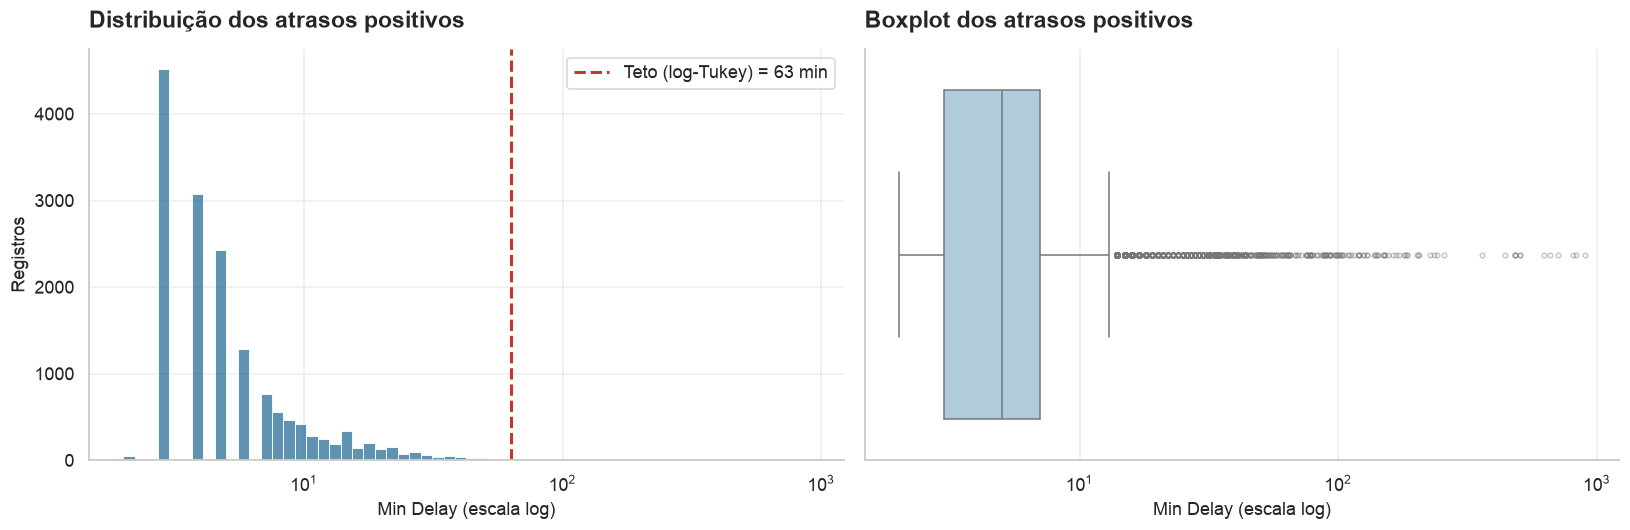

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

positive_delay = clean_df.loc[clean_df["Min Delay"] > 0, "Min Delay"]
sns.histplot(positive_delay, bins=60, log_scale=True, color="#2A6F97", ax=axes[0])
axes[0].axvline(OUTLIER_FENCES["Min Delay"], color="#C0392B", ls="--", lw=2,
                label=f"Teto (log-Tukey) = {OUTLIER_FENCES['Min Delay']:.0f} min")
axes[0].legend()
style_axis(axes[0], "Distribuição dos atrasos positivos", "Min Delay (escala log)", "Registros")

sns.boxplot(data=clean_df[clean_df["Min Delay"] > 0], x="Min Delay", color="#A9CCE3", ax=axes[1],
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
axes[1].set_xscale("log")
style_axis(axes[1], "Boxplot dos atrasos positivos", "Min Delay (escala log)")

plt.tight_layout()
plt.show()

> **Leitura:** em escala log, os atrasos positivos se aproximam de uma distribuição normal, o que valida o método. Uma
> pequena fração de eventos extremos concentra uma parcela desproporcional dos minutos totais — remover esses registros
> esconderia justamente os episódios mais graves (por exemplo, as tempestades de inverno).

In [19]:
print(f"Registros após o pré-processamento: {len(clean_df):,} "
      f"({len(clean_df) / len(raw_df):.2%} da base original)")

Registros após o pré-processamento: 45,338 (99.70% da base original)


---
## 3. Data Transformation — Transformação & Feature Engineering

**Objetivo:** derivar atributos que tornem os padrões mineráveis e compreensíveis:

| Nova coluna | Regra |
|---|---|
| `Hour` | Hora do dia (0–23) extraída de `Time` |
| `Is_Rush_Hour` | `True` se o horário está em **[07:00, 09:00)** ou **[16:00, 18:00)** |
| `Period_of_Day` | Faixa do dia (Madrugada, Pico Manhã, Entrepico, Pico Tarde, Noite) |
| `Is_Weekend` | Sábado ou domingo |
| `Has_Delay` | `Min Delay > 0` (o incidente efetivamente atrasou o serviço) |
| `Incident_Department` | Departamento TTC responsável, pela 1ª letra do código |
| `Incident_Category` | Categoria temática da causa (legível para negócio) |
| `Code_Description` | Descrição oficial do código TTC |
| `Line_Name` | Nome por extenso da linha |

### 3.1 Atributos temporais

In [20]:
def is_rush_hour(moment: time) -> bool:
    return any(start <= moment < end for start, end in RUSH_HOUR_WINDOWS)


def period_of_day(hour: int) -> str:
    if hour < 6:
        return "Madrugada (00–06h)"
    if hour < 9:
        return "Manhã / Pico (06–09h)"
    if hour < 16:
        return "Entrepico (09–16h)"
    if hour < 19:
        return "Tarde / Pico (16–19h)"
    return "Noite (19–24h)"


def add_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Hour"] = out["Timestamp"].dt.hour
    out["Is_Rush_Hour"] = out["Time"].map(is_rush_hour)
    out["Period_of_Day"] = out["Hour"].map(period_of_day)
    out["Day"] = pd.Categorical(out["Day"], categories=WEEKDAY_ORDER, ordered=True)
    out["Day_PT"] = pd.Categorical(out["Day"].map(WEEKDAY_PT), categories=list(WEEKDAY_PT.values()), ordered=True)
    out["Is_Weekend"] = out["Day"].isin(["Saturday", "Sunday"])
    out["Year_Month"] = out["Date"].dt.to_period("M")
    out["Has_Delay"] = out["Min Delay"] > 0
    return out


df = add_temporal_features(clean_df)
df[["Time", "Hour", "Is_Rush_Hour", "Period_of_Day", "Day_PT", "Is_Weekend"]].sample(6, random_state=7)

,Time,Hour,Is_Rush_Hour,Period_of_Day,Day_PT,Is_Weekend
28069,05:39:00,5,False,Madrugada (00–06h),Quinta,False
44425,20:47:00,20,False,Noite (19–24h),Terça,False
16009,06:06:00,6,False,Manhã / Pico (06–09h),Quinta,False
27988,06:02:00,6,False,Manhã / Pico (06–09h),Quinta,False
21267,23:55:00,23,False,Noite (19–24h),Sexta,False
8939,14:58:00,14,False,Entrepico (09–16h),Quarta,False


### 3.2 Categorização dos códigos de incidente

#### ⚠️ Nota metodológica sobre o padrão oficial da TTC

A especificação inicial do projeto sugeria interpretar a primeira letra do código como
*M = Mecânico, P = Passageiros, S = Sinalização, E/W = Clima*. Ao cruzar com o **codebook oficial da TTC**
(arquivo *Code Descriptions* publicado junto ao dataset no Portal de Dados Abertos de Toronto), essa leitura não se
sustenta. Exemplos:

| Código | Descrição oficial | Leitura sugerida | Realidade |
|---|---|---|---|
| `SUDP` | Disorderly Patron | Sinalização | Conduta de passageiro (Segurança) |
| `MUIS` | Injured or ill Customer (In Station) | Mecânico | Emergência médica |
| `PUOPO` | OPTO (COMMS) Train Door Monitoring | Passageiros | Sistema de monitoramento de portas |
| `EUDO` | Door Problems - Faulty Equipment | Clima | Falha de equipamento do trem |

Além disso, o prefixo **`T`** (operação/tripulação) — milhares de registros — não estava previsto, e não existem códigos
com prefixo `W` no período analisado.

A primeira letra indica, na verdade, o **departamento responsável** (o segundo caractere `U` indica *subway*):

| Prefixo | Departamento TTC | Exemplos |
|---|---|---|
| `E` | Equipamento — Material Rodante (*Rail Cars & Shops*) | freios, portas, propulsão |
| `M` | Diversos (*Miscellaneous*) | emergências médicas, alarmes, clima, incêndio |
| `P` | Infraestrutura fixa (*Plant*) | via, sinalização, energia, escadas rolantes |
| `S` | Segurança (*Security*) | passageiro desordeiro, agressão, invasão de via |
| `T` | Transporte — Operação/Tripulação (*Transportation*) | operador ausente, avanço de sinal |

Como o departamento `M` ("Diversos") mistura causas muito diferentes, criamos **duas camadas**:

1. **`Incident_Department`** — fiel ao padrão oficial (prefixo);
2. **`Incident_Category`** — categoria **temática** construída a partir da descrição oficial de cada código. É ela que
   responde "qual o motivo do atraso" em linguagem de negócio. Códigos ausentes do mapeamento explícito recebem a
   categoria do seu departamento (*fallback* por prefixo), garantindo cobertura de 100%.

In [21]:
DEPARTMENT_BY_PREFIX = {
    "E": "Equipamento / Material Rodante",
    "M": "Diversos (Miscellaneous)",
    "P": "Infraestrutura Fixa (Plant)",
    "S": "Segurança (Security)",
    "T": "Operação / Tripulação",
}

CODE_DESCRIPTIONS = {
    "EUAC": "Air Conditioning", "EUATC": "ATC RC&S Equipment", "EUBK": "Brakes", "EUBO": "Body",
    "EUCD": "Consequential Delay (2nd Delay Same Fault)", "EUDO": "Door Problems - Faulty Equipment",
    "EUECD": "ECD / Line Mechanic Related Prob.", "EUNEA": "No Equipment Available",
    "EUNT": "Equipment - No Trouble Found", "EUO": "RC&S Other", "EUPI": "Propulsion System",
    "EUSC": "Speed Control Equipment", "EUTL": "Trainline System", "EUVE": "Work Vehicle",
    "EUYRD": "Yard/Carhouse Related Problems",
    "MUATC": "ATC Project", "MUD": "Door Problems - Passenger Related", "MUDD": "Door Problems - Debris Related",
    "MUESA": "No Operator Immediately Available", "MUFM": "Force Majeure",
    "MUFS": "Fire/Smoke Plan B - Source External to TTC", "MUGD": "Miscellaneous General Delays",
    "MUI": "Injured or ill Customer (On Train) - Transported", "MUIE": "Injured Employee",
    "MUIR": "Injured or ill Customer (On Train) - Medical Aid Refused",
    "MUIRS": "Injured or ill Customer (In Station) - Medical Aid Refused",
    "MUIS": "Injured or ill Customer (In Station) - Transported", "MULD": "Labour Dispute - Subway",
    "MUNOA": "No Operator Immediately Available - Not E.S.A. Related", "MUO": "Miscellaneous Other",
    "MUPAA": "Passenger Assistance Alarm Activated - No Trouble Found", "MUPLA": "Fire/Smoke Plan A",
    "MUPLB": "Fire/Smoke Plan B - Source TTC", "MUPR1": "Priority One - Train in Contact With Person",
    "MUSAN": "Unsanitary Vehicle", "MUSC": "Miscellaneous Speed Control",
    "MUTD": "Training Department Related Delays", "MUTO": "Misc. Transportation Other - Employee Non-Chargeable",
    "MUWEA": "Weather Reports / Related Delays", "MUWR": "Work Refusal",
    "PUATC": "ATC Signals Other", "PUCSC": "Signal Control Problem - Signals", "PUDCS": "Data Communications System Failure",
    "PUMEL": "Escalator/Elevator Incident", "PUMO": "Station Other", "PUMST": "Station Stairway Incident",
    "PUOPO": "OPTO (COMMS) Train Door Monitoring", "PUSAC": "Signals Axle Counter Block Failure",
    "PUSCA": "SCADA Related Problems", "PUSI": "Signals or Related Components Failure",
    "PUSIS": "Signals Track Weather Related", "PUSNT": "Signal Problem - No Trouble",
    "PUSRA": "Subway Radio System Fault", "PUSSW": "Track Switch Failure - Signal Related Problem",
    "PUSTC": "Signals - Track Circuit Problems", "PUSTP": "Traction Power or Related Components Failure",
    "PUSTS": "Signals - Train Stops", "PUSWZ": "Work Zone Problems - Signals", "PUTD": "Track Level Debris - Controllable",
    "PUTDN": "Debris At Track Level - Uncontrollable", "PUTIS": "Ice / Snow Related Problems", "PUTO": "T&S Other",
    "PUTOE": "T & S Operator Related Problems", "PUTR": "Rail Related Problem", "PUTS": "Structure Related Problem",
    "PUTSM": "Track Switch Failure - Track Related Problem", "PUTTP": "Traction Power Rail Related",
    "PUTWZ": "Work Zone Problems - Track",
    "SUAE": "Assault / Employee Involved", "SUAP": "Assault / Patron Involved", "SUBT": "Bomb Threat",
    "SUCOL": "Collector Booth Alarm Activated", "SUDP": "Disorderly Patron",
    "SUEAS": "Emergency Alarm Station Activation", "SUG": "Graffiti / Scratchiti", "SUO": "Passenger Other",
    "SUPOL": "Held By Police - Non-TTC Related", "SUROB": "Robbery", "SUSA": "Sexual Assault",
    "SUSP": "Suspicious Package", "SUUT": "Unauthorized at Track Level",
    "TUATC": "ATC Operator Related", "TUCC": "Transit Control Related Problems", "TUDOE": "Doors Open in Error",
    "TUKEY": "Two Drum Switch Keys Activated", "TUML": "Mainline Storage", "TUMVS": "Operator Violated Signal",
    "TUNIP": "Operator Not In Position", "TUNOA": "No Operator Immediately Available",
    "TUO": "Transportation Department - Other", "TUOPO": "OPTO Operator Related", "TUOS": "Operator Overshot Platform",
    "TUS": "Crew Unable to Maintain Schedule", "TUSC": "Operator Overspeeding",
    "TUSET": "Train Controls Improperly Shut Down", "TUST": "Storm Trains", "TUSUP": "Supervisory Error",
}

CATEGORY_BY_CODE = {
    "Emergências Médicas / Pessoas Feridas": {"MUI", "MUIR", "MUIRS", "MUIS", "MUIE", "MUPR1"},
    "Alarmes de Passageiro (sem falha)": {"MUPAA", "SUEAS", "SUCOL"},
    "Segurança & Conduta de Passageiros": {
        "SUDP", "SUO", "SUAP", "SUAE", "SUUT", "SUG", "SUSP", "SUBT", "SUROB", "SUSA", "SUPOL", "MUD",
    },
    "Material Rodante & Equipamentos": {"MUSC", "MUDD"},
    "Sinalização & Sistemas de Controle": {
        "PUATC", "PUCSC", "PUCSS", "PUCBI", "PUDCS", "PUOPO", "PUSAC", "PUSBE", "PUSCA", "PUSCR", "PUSEA", "PUSI",
        "PUSIO", "PUSLC", "PUSNT", "PUSO", "PUSRA", "PUSSW", "PUSTC", "PUSTS", "PUSWZ", "PUSZC", "MUATC",
    },
    "Via, Energia & Estações": {
        "PUSTP", "PUTR", "PUTS", "PUTSM", "PUTTP", "PUTTC", "PUTIJ", "PUTWZ", "PUTSC", "PUTCD", "PUTNT", "PUTO",
        "PUMEL", "PUMO", "PUMST", "MUEC", "MUODC",
    },
    "Operação & Tripulação": {"MUNOA", "MUESA", "MUTO", "MUCL", "MUTD", "MULD", "MUWR", "PUTOE"},
    "Clima, Incêndio & Fatores Externos": {
        "MUWEA", "MUFM", "PUTIS", "PUSIS", "MUFS", "MUPLA", "MUPLB", "MUPLC", "PUTDN",
    },
    "Limpeza & Higiene": {"MUSAN", "PUTD"},
    "Outros / Não especificado": {"MUO", "MUGD", "EUCD"},
}
CODE_TO_CATEGORY = {code: category for category, codes in CATEGORY_BY_CODE.items() for code in codes}

CATEGORY_FALLBACK_BY_PREFIX = {
    "E": "Material Rodante & Equipamentos",
    "P": "Via, Energia & Estações",
    "S": "Segurança & Conduta de Passageiros",
    "T": "Operação & Tripulação",
}
OTHER_CATEGORY = "Outros / Não especificado"


def incident_department(code: str) -> str:
    return DEPARTMENT_BY_PREFIX.get(str(code)[:1].upper(), "Outros")


def incident_category(code: str) -> str:
    # Regra explícita pelo código; senão, fallback pelo departamento (prefixo); senão, "Outros".
    code = str(code).upper().strip()
    if code in CODE_TO_CATEGORY:
        return CODE_TO_CATEGORY[code]
    return CATEGORY_FALLBACK_BY_PREFIX.get(code[:1], OTHER_CATEGORY)


def add_incident_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Code"] = out["Code"].str.upper().str.strip()
    out["Incident_Department"] = out["Code"].map(incident_department)
    out["Incident_Category"] = out["Code"].map(incident_category)
    out["Code_Description"] = out["Code"].map(CODE_DESCRIPTIONS).fillna("(sem descrição no codebook de referência)")
    out["Category_Source"] = np.where(out["Code"].isin(CODE_TO_CATEGORY), "regra explícita", "fallback por prefixo")
    return out


df = add_incident_features(df)
print("Origem da categorização:")
print(df["Category_Source"].value_counts(normalize=True).map(pct).to_string())
print("\nCódigos mais frequentes classificados por fallback de prefixo:")
print(df.loc[df["Category_Source"] == "fallback por prefixo", ["Code", "Code_Description", "Incident_Category"]]
        .value_counts().head(10).to_string())

Origem da categorização:
Category_Source
regra explícita         78.7%
fallback por prefixo    21.3%

Códigos mais frequentes classificados por fallback de prefixo:
Code   Code_Description                           Incident_Category                 
TUNCA  (sem descrição no codebook de referência)  Operação & Tripulação                 1162
SUL    (sem descrição no codebook de referência)  Segurança & Conduta de Passageiros    1131
MUNCA  (sem descrição no codebook de referência)  Outros / Não especificado              958
TUSC   Operator Overspeeding                      Operação & Tripulação                  849
TUO    Transportation Department - Other          Operação & Tripulação                  837
EUSC   Speed Control Equipment                    Material Rodante & Equipamentos        802
MUCP   (sem descrição no codebook de referência)  Outros / Não especificado              374
TUMVS  Operator Violated Signal                   Operação & Tripulação                  366
EUDO  

> Cerca de 3/4 dos registros são classificados por **regra explícita**. O *fallback* cobre dois grupos:
> (i) códigos `T` e `E` cujo departamento já define o tema (ex.: `TUSC` *Operator Overspeeding* → Operação & Tripulação;
> `EUSC` *Speed Control Equipment* → Material Rodante); e (ii) códigos **novos, ausentes do codebook de referência**
> (ex.: `TUNCA`, `SUL`, `MUNCA`, `MUINF`), que herdam a categoria do seu departamento oficial. Códigos `M` sem descrição
> vão para *Outros*, sem que inventemos um significado.

### 3.3 Nomes das linhas e base analítica final

In [22]:
def add_line_names(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["Line_Name"] = out["Line_Std"].map(LINES_IN_SCOPE).fillna(MULTI_LINE_LABEL)
    return out


ANALYTICAL_COLUMNS = [
    "_id", "Timestamp", "Date", "Time", "Day", "Day_PT", "Hour", "Is_Rush_Hour", "Period_of_Day", "Is_Weekend",
    "Year_Month", "Station", "Station_Std", "Is_Station", "Line_Std", "Line_Name", "Bound", "Vehicle",
    "Code", "Code_Description", "Incident_Department", "Incident_Category",
    "Min Delay", "Min Gap", "Min Delay_Capped", "Min Gap_Capped", "Has_Delay", "Is_Extreme_Delay",
]

df = add_line_names(df)[ANALYTICAL_COLUMNS]
single_line_df = df[df["Line_Std"].isin(LINES_IN_SCOPE)]

print(f"Base analítica: {df.shape[0]:,} registros × {df.shape[1]} colunas")
print(f"Incidentes de linha única: {len(single_line_df):,} | Multi-linha: {(df['Line_Std'] == 'MULTI').sum():,}")
df.head()

Base analítica: 45,338 registros × 28 colunas
Incidentes de linha única: 44,743 | Multi-linha: 595


,_id,Timestamp,Date,Time,Day,Day_PT,Hour,Is_Rush_Hour,Period_of_Day,Is_Weekend,Year_Month,Station,Station_Std,Is_Station,Line_Std,Line_Name,Bound,Vehicle,Code,Code_Description,Incident_Department,Incident_Category,Min Delay,Min Gap,Min Delay_Capped,Min Gap_Capped,Has_Delay,Is_Extreme_Delay
0,1,2025-01-01 02:10:00,2025-01-01,02:10:00,Wednesday,Quarta,2,False,Madrugada (00–06h),False,2025-01,BATHURST STATION,BATHURST,True,BD,Bloor-Danforth,E,5227,MUSAN,Unsanitary Vehicle,Diversos (Miscellaneous),Limpeza & Higiene,5,9,5.00,9.00,True,False
1,2,2025-01-01 02:30:00,2025-01-01,02:30:00,Wednesday,Quarta,2,False,Madrugada (00–06h),False,2025-01,DUNDAS STATION,TMU,True,YU,Yonge-University,Unknown,<NA>,MUIRS,Injured or ill Customer (In Station) - Medical...,Diversos (Miscellaneous),Emergências Médicas / Pessoas Feridas,0,0,0.00,0.00,False,False
2,3,2025-01-01 02:32:00,2025-01-01,02:32:00,Wednesday,Quarta,2,False,Madrugada (00–06h),False,2025-01,BROADVIEW STATION,BROADVIEW,True,BD,Bloor-Danforth,E,<NA>,PUMST,Station Stairway Incident,Infraestrutura Fixa (Plant),"Via, Energia & Estações",0,0,0.00,0.00,False,False
3,4,2025-01-01 02:58:00,2025-01-01,02:58:00,Wednesday,Quarta,2,False,Madrugada (00–06h),False,2025-01,KEELE STATION,KEELE,True,BD,Bloor-Danforth,W,5293,EUSC,Speed Control Equipment,Equipamento / Material Rodante,Material Rodante & Equipamentos,0,0,0.00,0.00,False,False
4,5,2025-01-01 02:58:00,2025-01-01,02:58:00,Wednesday,Quarta,2,False,Madrugada (00–06h),False,2025-01,COXWELL STATION,COXWELL,True,BD,Bloor-Danforth,Unknown,<NA>,SUAE,Assault / Employee Involved,Segurança (Security),Segurança & Conduta de Passageiros,0,0,0.00,0.00,False,False


---
## 4. Data Mining — Mineração e Análise de Padrões

A mineração aqui é **descritiva**: agregações, rankings, normalizações e comparações estatísticas que revelam padrões
de frequência e severidade. Duas métricas guiam toda a análise:

- **Frequência** (nº de incidentes) → mede *quantas vezes* o sistema falha;
- **Severidade** (minutos de `Min Delay`) → mede *quanto* cada falha custa ao passageiro.

Uma causa pode ser muito frequente e pouco severa (ex.: alarmes sem falha) ou rara e devastadora (ex.: neve).
A função abaixo calcula, para qualquer agrupamento, o mesmo conjunto padronizado de indicadores.

In [23]:
def summarize(df: pd.DataFrame, by) -> pd.DataFrame:
    # Indicadores padronizados de frequência e severidade para qualquer agrupamento.
    summary = (
        df.groupby(by, observed=True)
          .agg(
              Incidentes=("Code", "size"),
              Minutos_Atraso=("Min Delay", "sum"),
              Atraso_Medio=("Min Delay", "mean"),
              Atraso_Medio_Robusto=("Min Delay_Capped", "mean"),
              Gap_Medio=("Min Gap", "mean"),
              Pct_Com_Atraso=("Has_Delay", "mean"),
          )
    )
    summary["Pct_Incidentes"] = summary["Incidentes"] / summary["Incidentes"].sum()
    summary["Pct_Minutos"] = summary["Minutos_Atraso"] / summary["Minutos_Atraso"].sum()
    return summary


def show(summary: pd.DataFrame):
    # Exibe um resumo com formatação legível (percentuais e milhares).
    return summary.style.format({
        "Incidentes": "{:,.0f}", "Minutos_Atraso": "{:,.0f}", "Atraso_Medio": "{:.2f}",
        "Atraso_Medio_Robusto": "{:.2f}", "Gap_Medio": "{:.2f}", "Pct_Com_Atraso": "{:.1%}",
        "Pct_Incidentes": "{:.1%}", "Pct_Minutos": "{:.1%}",
    }).background_gradient(subset=["Incidentes", "Minutos_Atraso"], cmap="Blues")

### 4.1 Pergunta 1 — Volume de ocorrências e principais motivos

In [24]:
category_summary = summarize(df, "Incident_Category").sort_values("Incidentes", ascending=False)
show(category_summary)

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Incident_Category,,,,,,,,
Segurança & Conduta de Passageiros,"12,865","31,451",2.44,2.42,3.66,31.3%,28.4%,25.8%
Emergências Médicas / Pessoas Feridas,"8,913","17,764",1.99,1.86,2.79,21.4%,19.7%,14.6%
Operação & Tripulação,"5,015","11,887",2.37,2.36,3.76,43.6%,11.1%,9.7%
Material Rodante & Equipamentos,"4,253","12,575",2.96,2.79,4.26,44.4%,9.4%,10.3%
Outros / Não especificado,"3,417","2,954",0.86,0.86,1.21,14.6%,7.5%,2.4%
"Via, Energia & Estações","3,416","10,821",3.17,2.53,2.51,25.5%,7.5%,8.9%
Sinalização & Sistemas de Controle,"3,410","11,901",3.49,3.28,5.11,51.4%,7.5%,9.8%
Alarmes de Passageiro (sem falha),"2,499","6,495",2.60,2.60,4.71,55.2%,5.5%,5.3%
Limpeza & Higiene,785,"3,304",4.21,4.21,7.68,93.0%,1.7%,2.7%


In [25]:
department_summary = summarize(df, "Incident_Department").sort_values("Incidentes", ascending=False)
show(department_summary)

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Incident_Department,,,,,,,,
Diversos (Miscellaneous),"18,591","41,812",2.25,2.01,3.32,30.9%,41.0%,34.3%
Segurança (Security),"12,736","31,695",2.49,2.47,3.69,30.9%,28.1%,26.0%
Infraestrutura Fixa (Plant),"7,146","28,056",3.93,3.08,4.22,39.6%,15.8%,23.0%
Operação / Tripulação,"4,339","9,786",2.26,2.25,3.51,40.4%,9.6%,8.0%
Equipamento / Material Rodante,"2,522","10,604",4.20,3.92,5.86,60.8%,5.6%,8.7%
Outros,4,0,0.00,0.00,0.00,0.0%,0.0%,0.0%


In [26]:
top_codes = (
    summarize(df, ["Code", "Code_Description", "Incident_Category"])
      .sort_values("Incidentes", ascending=False)
      .head(15)
)
show(top_codes)

,,,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Code,Code_Description,Incident_Category,,,,,,,,
SUDP,Disorderly Patron,Segurança & Conduta de Passageiros,"5,166","12,098",2.34,2.33,3.80,37.1%,11.4%,9.9%
MUIS,Injured or ill Customer (In Station) - Transported,Emergências Médicas / Pessoas Feridas,"4,260",369,0.09,0.09,0.13,1.1%,9.4%,0.3%
SUO,Passenger Other,Segurança & Conduta de Passageiros,"3,268","6,305",1.93,1.89,2.84,22.6%,7.2%,5.2%
MUPAA,Passenger Assistance Alarm Activated - No Trouble Found,Alarmes de Passageiro (sem falha),"2,405","5,396",2.24,2.24,4.30,53.8%,5.3%,4.4%
PUOPO,OPTO (COMMS) Train Door Monitoring,Sinalização & Sistemas de Controle,"2,336","5,355",2.29,2.29,3.97,46.7%,5.2%,4.4%
MUIRS,Injured or ill Customer (In Station) - Medical Aid Refused,Emergências Médicas / Pessoas Feridas,"2,046",300,0.15,0.15,0.25,2.6%,4.5%,0.2%
MUIR,Injured or ill Customer (On Train) - Medical Aid Refused,Emergências Médicas / Pessoas Feridas,"1,574","8,501",5.40,5.40,8.33,77.3%,3.5%,7.0%
MUSC,Miscellaneous Speed Control,Material Rodante & Equipamentos,"1,455",552,0.38,0.38,0.73,9.2%,3.2%,0.5%
MUO,Miscellaneous Other,Outros / Não especificado,"1,414","2,169",1.53,1.53,2.12,25.6%,3.1%,1.8%


> ### 💡 Insights — Pergunta 1: Volume e principais motivos
>
> - **O maior gerador de incidentes não é técnico, é humano.** *Segurança & Conduta de Passageiros* lidera com
>   **~28% dos incidentes e ~26% dos minutos**; somada a *Emergências Médicas* (~20%), quase metade de todas as ocorrências
>   envolve diretamente pessoas — e não trens, trilhos ou sinais.
> - **`SUDP` (Disorderly Patron) é o código mais frequente da rede** (~5,2 mil registros, ~11%) e também o que mais
>   acumula minutos entre os códigos individuais (~12 mil).
> - **Frequência ≠ impacto.** `MUIS` (passageiro ferido/doente na estação) é o 2º código mais frequente, mas só ~1% desses
>   registros atrasa o serviço (média de 0,09 min). Já `MUIR` (passageiro doente **dentro do trem**, recusa atendimento)
>   gera 5,4 min médios, porque o trem fica retido na plataforma.
> - **Causas técnicas** (Material Rodante, Sinalização, Via/Energia) somam ~25% dos incidentes e ~29% dos minutos:
>   são menos frequentes, mas cada ocorrência custa mais.
> - Pelo padrão oficial de departamentos, *Diversos (M)* concentra 41% dos registros — o que justifica a camada temática:
>   o prefixo sozinho esconderia que esse grupo mistura emergências médicas, alarmes, clima e limpeza.
>
> **Implicação prática:** programas de segurança e acolhimento na plataforma (agentes, equipes de saúde, campanhas de
> conduta) atacam a maior fatia do volume; manutenção preventiva ataca as falhas mais caras por ocorrência.

### 4.2 Pergunta 2 — Padrões temporais (vulnerabilidade do sistema)

#### 4.2.1 Distribuição por dia da semana

Como o período não tem exatamente o mesmo número de cada dia da semana, além do total calculamos a
**média de incidentes por dia** (total ÷ nº de datas daquele dia da semana).

In [27]:
days_in_period = df.groupby("Day_PT", observed=True)["Date"].nunique().rename("Dias_no_Periodo")
weekday_summary = summarize(df, "Day_PT").join(days_in_period)
weekday_summary["Incidentes_por_Dia"] = weekday_summary["Incidentes"] / weekday_summary["Dias_no_Periodo"]
weekday_summary["Minutos_por_Dia"] = weekday_summary["Minutos_Atraso"] / weekday_summary["Dias_no_Periodo"]

show(weekday_summary).format({"Incidentes_por_Dia": "{:.1f}", "Minutos_por_Dia": "{:,.0f}"}, subset=["Incidentes_por_Dia", "Minutos_por_Dia"])

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos,Dias_no_Periodo,Incidentes_por_Dia,Minutos_por_Dia
Day_PT,,,,,,,,,,,
Segunda,"6,776","18,572",2.74,2.34,3.39,34.4%,14.9%,15.2%,87,77.9,213
Terça,"6,724","17,493",2.60,2.43,3.52,36.0%,14.8%,14.3%,86,78.2,203
Quarta,"6,931","17,592",2.54,2.34,3.63,35.5%,15.3%,14.4%,87,79.7,202
Quinta,"7,054","18,357",2.60,2.50,3.67,35.4%,15.6%,15.1%,87,81.1,211
Sexta,"6,960","17,917",2.57,2.44,3.58,35.0%,15.4%,14.7%,87,80.0,206
Sábado,"5,735","14,167",2.47,2.40,3.81,33.7%,12.6%,11.6%,87,65.9,163
Domingo,"5,158","17,855",3.46,2.64,4.76,33.4%,11.4%,14.6%,87,59.3,205


In [28]:
weekday_rate = weekday_summary["Incidentes_por_Dia"]
weekend_mask = weekday_rate.index.isin(["Sábado", "Domingo"])
print(f"Média de incidentes/dia — dias úteis: {weekday_rate[~weekend_mask].mean():.1f} | "
      f"fim de semana: {weekday_rate[weekend_mask].mean():.1f} "
      f"({weekday_rate[~weekend_mask].mean() / weekday_rate[weekend_mask].mean() - 1:+.1%} nos dias úteis)")

Média de incidentes/dia — dias úteis: 79.4 | fim de semana: 62.6 (+26.8% nos dias úteis)


#### 4.2.2 Densidade por hora do dia e Rush Hour vs. horário normal

Comparar totais brutos seria injusto: o pico tem só **4 horas/dia** contra 20 horas no "normal" (que inclui a madrugada,
quando o metrô quase não opera). Por isso comparamos a **taxa por hora** — incidentes e minutos por hora de janela —
e restringimos o "horário normal" às horas com serviço regular (06h–01h).

In [29]:
hourly_summary = summarize(df, "Hour").reindex(range(24), fill_value=0)
hourly_summary["Is_Rush_Hour"] = [is_rush_hour(time(h, 0)) for h in hourly_summary.index]
show(hourly_summary.drop(columns="Is_Rush_Hour"))

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Hour,,,,,,,,
0,"1,604","3,772",2.35,2.30,3.95,30.2%,3.5%,3.1%
1,"1,679","3,860",2.30,2.30,3.66,27.4%,3.7%,3.2%
2,988,721,0.73,0.73,0.97,6.9%,2.2%,0.6%
3,260,89,0.34,0.34,0.40,3.1%,0.6%,0.1%
4,212,548,2.58,0.89,2.16,4.2%,0.5%,0.4%
5,"1,588","8,368",5.27,3.87,2.21,41.1%,3.5%,6.9%
6,"2,033","7,424",3.65,3.11,3.69,49.5%,4.5%,6.1%
7,"2,067","4,457",2.16,2.13,2.96,36.7%,4.6%,3.7%
8,"2,664","6,619",2.48,2.43,3.28,38.0%,5.9%,5.4%


In [30]:
SERVICE_HOURS = set(range(6, 24)) | {0, 1}


def rush_vs_normal(df: pd.DataFrame, service_hours=SERVICE_HOURS) -> pd.DataFrame:
    # Compara pico e horário normal por taxa horária, para neutralizar a diferença no tamanho das janelas.
    in_service = df[df["Hour"].isin(service_hours)]
    n_days = df["Date"].nunique()
    window_hours = {True: 4, False: len(service_hours) - 4}
    result = summarize(in_service, "Is_Rush_Hour")
    result["Horas_Janela_por_Dia"] = [window_hours[flag] for flag in result.index]
    result["Incidentes_por_Hora"] = result["Incidentes"] / (result["Horas_Janela_por_Dia"] * n_days)
    result["Minutos_por_Hora"] = result["Minutos_Atraso"] / (result["Horas_Janela_por_Dia"] * n_days)
    return result.rename(index={True: "Rush Hour", False: "Horário Normal"})


rush_summary = rush_vs_normal(df)
show(rush_summary).format({"Incidentes_por_Hora": "{:.2f}", "Minutos_por_Hora": "{:.2f}"}, subset=["Incidentes_por_Hora", "Minutos_por_Hora"])

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos,Horas_Janela_por_Dia,Incidentes_por_Hora,Minutos_por_Hora
Is_Rush_Hour,,,,,,,,,,,
Horário Normal,"32,520","86,309",2.65,2.44,3.93,34.7%,76.9%,76.9%,16,3.34,8.87
Rush Hour,"9,770","25,918",2.65,2.47,3.69,38.7%,23.1%,23.1%,4,4.02,10.66


In [31]:
rush_weekday = rush_vs_normal(df[~df["Is_Weekend"]])
rush_lift = rush_summary.loc["Rush Hour", "Incidentes_por_Hora"] / rush_summary.loc["Horário Normal", "Incidentes_por_Hora"] - 1
rush_lift_weekday = rush_weekday.loc["Rush Hour", "Incidentes_por_Hora"] / rush_weekday.loc["Horário Normal", "Incidentes_por_Hora"] - 1
minutes_lift = rush_summary.loc["Rush Hour", "Minutos_por_Hora"] / rush_summary.loc["Horário Normal", "Minutos_por_Hora"] - 1

print(f"Incidentes/hora no pico vs normal (todos os dias): {rush_lift:+.1%}")
print(f"Incidentes/hora no pico vs normal (só dias úteis): {rush_lift_weekday:+.1%}")
print(f"Minutos de atraso/hora no pico vs normal        : {minutes_lift:+.1%}")
print(f"Atraso médio por incidente — pico: {rush_summary.loc['Rush Hour', 'Atraso_Medio']:.2f} min | "
      f"normal: {rush_summary.loc['Horário Normal', 'Atraso_Medio']:.2f} min")

Incidentes/hora no pico vs normal (todos os dias): +20.2%


Incidentes/hora no pico vs normal (só dias úteis): +25.7%
Minutos de atraso/hora no pico vs normal        : +20.1%
Atraso médio por incidente — pico: 2.65 min | normal: 2.65 min


#### 4.2.3 Matriz Dia da Semana × Hora do Dia

A matriz cruza as duas dimensões temporais e mostra a **média de incidentes por dia** em cada célula (total ÷ nº de
datas daquele dia da semana) — ela é a base do heatmap da seção 5.

In [32]:
weekday_hour_matrix = (
    df.pivot_table(index="Day_PT", columns="Hour", values="Code", aggfunc="size", fill_value=0, observed=True)
      .reindex(columns=range(24), fill_value=0)
      .div(days_in_period, axis=0)
)
weekday_hour_matrix.round(2)

Hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Day_PT,,,,,,,,,,,,,,,,,,,,,,,,
Segunda,2.26,2.70,1.67,0.55,0.53,3.47,4.10,3.70,5.20,3.76,3.06,2.76,3.54,3.45,3.53,3.77,4.02,4.28,4.18,3.13,2.98,3.20,4.22,3.84
Terça,2.45,2.56,1.49,0.37,0.45,2.69,4.31,4.00,4.80,3.86,3.14,3.14,3.55,3.42,3.20,3.76,4.60,4.80,3.99,3.15,3.48,3.29,4.19,3.50
Quarta,2.64,2.71,1.70,0.39,0.33,2.57,4.11,3.87,4.69,3.78,2.89,3.30,3.29,3.32,3.95,4.49,4.69,4.49,4.16,3.33,3.47,3.28,4.45,3.74
Quinta,2.95,2.70,1.53,0.36,0.33,2.94,3.71,4.46,4.97,3.77,3.29,3.03,3.45,3.39,3.79,3.93,5.05,4.75,4.23,3.25,3.52,3.29,4.71,3.68
Sexta,2.79,3.16,1.44,0.54,0.36,3.51,3.87,3.80,4.03,3.38,2.95,3.34,3.97,3.37,3.91,3.93,3.92,4.26,4.20,3.17,3.25,3.72,4.66,4.46
Sábado,2.76,2.79,1.83,0.38,0.28,2.82,2.87,1.94,2.09,2.28,2.31,3.54,3.02,3.39,3.14,2.95,3.16,3.43,3.47,3.01,3.38,3.23,4.62,3.23
Domingo,2.60,2.70,1.72,0.40,0.16,0.29,0.43,2.02,4.90,2.34,2.57,2.97,2.51,2.98,2.93,3.03,3.36,3.22,3.18,3.02,2.51,2.80,4.07,2.57


In [33]:
peak_cells = weekday_hour_matrix.stack().sort_values(ascending=False).head(8)
print("Combinações Dia × Hora mais críticas (incidentes médios por dia):")
for (day, hour), value in peak_cells.items():
    print(f"  {day:<8} {hour:02d}h → {value:.2f}")

Combinações Dia × Hora mais críticas (incidentes médios por dia):
  Segunda  08h → 5.20
  Quinta   16h → 5.05
  Quinta   08h → 4.97
  Domingo  08h → 4.90
  Terça    08h → 4.80
  Terça    17h → 4.80
  Quinta   17h → 4.75
  Quinta   22h → 4.71


> ### 💡 Insights — Pergunta 2: Padrões temporais
>
> - **Dias úteis são ~27% mais carregados** que o fim de semana (~79 vs. ~63 incidentes/dia), acompanhando a demanda.
>   Quinta-feira é o dia com mais incidentes por dia (~81).
> - **Domingo é o dia menos frequente, mas com o maior atraso médio** (3,46 min vs. ~2,6 nos demais): as duas maiores
>   tempestades de neve do período (16/02/2025 e 25–26/01/2026) começaram em domingos. Isso mostra como poucos eventos
>   extremos distorcem médias — por isso também reportamos métricas robustas.
> - **O pico é mais vulnerável em frequência, não em severidade.** Na comparação normalizada por hora, o Rush Hour tem
>   **+20% de incidentes/hora** (+26% considerando só dias úteis) e +20% de minutos/hora — mas o atraso médio por
>   incidente é **idêntico** (2,65 min). Ou seja: o pico gera *mais* falhas, não falhas *piores*; o volume de passageiros
>   multiplica as oportunidades de incidente.
> - **A curva horária tem três picos:** 08h (pico da manhã), 16–17h (pico da tarde) e um pico às **22h**, que é a hora
>   com mais registros do dia. Esse último é dominado por códigos administrativos/genéricos (`MUO`, `MUINF`) — padrão
>   compatível com o encerramento antecipado para obras noturnas e com registros informativos, não com um aumento real de
>   falhas operacionais.
> - **Início de operação é um momento crítico:** às 05–06h predominam falhas de partida (monitoramento de portas `PUOPO`,
>   zonas de obra remanescentes `PUTWZ`, falta de tripulação `TUNCA`/`MUNCA`). No domingo, o salto ocorre às **08h** —
>   o volume quase nulo antes das 07h é coerente com o início mais tardio do serviço aos domingos.

### 4.3 Pergunta 3 — Análise por linhas e estações

#### 4.3.1 Linhas

Além dos totais, normalizamos pelo **número de estações** de cada linha (38 na YU, 31 na BD, 5 na SHP), pois a
Sheppard é muito menor e totais absolutos naturalmente a colocariam por último.

In [34]:
line_summary = summarize(df, "Line_Name").sort_values("Minutos_Atraso", ascending=False)
stations_per_line = {LINES_IN_SCOPE[code]: len(stations) for code, stations in OFFICIAL_STATIONS.items()}
line_summary["Estacoes"] = line_summary.index.map(stations_per_line)
line_summary["Incidentes_por_Estacao"] = line_summary["Incidentes"] / line_summary["Estacoes"]
line_summary["Minutos_por_Estacao"] = line_summary["Minutos_Atraso"] / line_summary["Estacoes"]

show(line_summary).format(
    {"Estacoes": "{:.0f}", "Incidentes_por_Estacao": "{:,.1f}", "Minutos_por_Estacao": "{:,.1f}"},
    subset=["Estacoes", "Incidentes_por_Estacao", "Minutos_por_Estacao"], na_rep="—",
)

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos,Estacoes,Incidentes_por_Estacao,Minutos_por_Estacao
Line_Name,,,,,,,,,,,
Yonge-University,"23,183","65,486",2.82,2.56,3.91,37.3%,51.1%,53.7%,38,610.1,"1,723.3"
Bloor-Danforth,"19,795","51,513",2.60,2.36,3.57,33.0%,43.7%,42.2%,31,638.5,"1,661.7"
Sheppard,"1,765","4,954",2.81,2.51,4.31,35.6%,3.9%,4.1%,5,353.0,990.8
Multi-linha,595,0,0.00,0.00,0.00,0.0%,1.3%,0.0%,—,—,—


In [35]:
line_category_minutes = (
    single_line_df.pivot_table(index="Incident_Category", columns="Line_Name", values="Min Delay",
                               aggfunc="sum", fill_value=0)
)
line_category_share = line_category_minutes.div(line_category_minutes.sum(axis=0), axis=1)
line_category_share.sort_values("Yonge-University", ascending=False).style.format("{:.1%}").background_gradient(cmap="Oranges")

Line_Name,Bloor-Danforth,Sheppard,Yonge-University
Incident_Category,,,
Segurança & Conduta de Passageiros,26.0%,14.8%,26.5%
Emergências Médicas / Pessoas Feridas,15.4%,5.7%,14.6%
Sinalização & Sistemas de Controle,6.3%,24.9%,11.3%
"Clima, Incêndio & Fatores Externos",11.2%,1.8%,10.6%
"Via, Energia & Estações",7.2%,16.9%,9.6%
Material Rodante & Equipamentos,13.7%,10.6%,7.7%
Alarmes de Passageiro (sem falha),2.8%,1.5%,7.6%
Operação & Tripulação,12.4%,19.3%,6.9%
Limpeza & Higiene,2.5%,2.2%,2.9%


#### 4.3.2 Estações mais críticas

In [36]:
station_summary = summarize(df[df["Is_Station"]], "Station_Std")
top10_by_minutes = station_summary.nlargest(10, "Minutos_Atraso")
top10_by_frequency = station_summary.nlargest(10, "Incidentes")

print("Top 10 por MINUTOS acumulados de atraso:")
display(show(top10_by_minutes))

Top 10 por MINUTOS acumulados de atraso:


,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Station_Std,,,,,,,,
BLOOR-YONGE,"2,995","5,211",1.74,1.72,2.59,28.0%,7.0%,4.4%
KIPLING,"1,743","4,507",2.59,2.28,3.89,41.0%,4.0%,3.8%
EGLINTON,"1,103","4,039",3.66,2.90,4.64,41.0%,2.6%,3.4%
KENNEDY,"1,863","3,834",2.06,1.98,3.29,36.4%,4.3%,3.2%
ST GEORGE,"1,390","3,754",2.70,2.66,3.84,39.6%,3.2%,3.2%
FINCH,"1,822","3,436",1.89,1.79,2.94,33.4%,4.2%,2.9%
SHEPPARD-YONGE,"1,055","3,351",3.18,2.88,4.87,39.1%,2.4%,2.8%
WILSON,930,"3,195",3.44,3.34,4.60,55.6%,2.2%,2.7%
VICTORIA PARK,797,"3,097",3.89,2.97,5.12,33.1%,1.9%,2.6%


In [37]:
print("Top 10 por FREQUÊNCIA de incidentes:")
show(top10_by_frequency)

Top 10 por FREQUÊNCIA de incidentes:


,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos
Station_Std,,,,,,,,
BLOOR-YONGE,"2,995","5,211",1.74,1.72,2.59,28.0%,7.0%,4.4%
KENNEDY,"1,863","3,834",2.06,1.98,3.29,36.4%,4.3%,3.2%
FINCH,"1,822","3,436",1.89,1.79,2.94,33.4%,4.2%,2.9%
KIPLING,"1,743","4,507",2.59,2.28,3.89,41.0%,4.0%,3.8%
ST GEORGE,"1,390","3,754",2.70,2.66,3.84,39.6%,3.2%,3.2%
VAUGHAN METROPOLITAN CENTRE,"1,181","1,954",1.65,1.65,2.83,32.5%,2.7%,1.7%
UNION,"1,157","2,507",2.17,2.07,2.73,30.0%,2.7%,2.1%
EGLINTON,"1,103","4,039",3.66,2.90,4.64,41.0%,2.6%,3.4%
SHEPPARD-YONGE,"1,055","3,351",3.18,2.88,4.87,39.1%,2.4%,2.8%


In [38]:
in_both = top10_by_minutes.index.intersection(top10_by_frequency.index)
print(f"Estações presentes nos dois rankings ({len(in_both)}): {', '.join(in_both)}")

top10_share = top10_by_frequency["Incidentes"].sum() / station_summary["Incidentes"].sum()
print(f"As 10 estações mais frequentes concentram {top10_share:.1%} dos incidentes "
      f"atribuídos a estações ({len(station_summary)} estações no total).")

top_station_causes = (
    df[df["Station_Std"].isin(top10_by_frequency.index)]
      .groupby("Station_Std")["Incident_Category"]
      .agg(lambda s: s.value_counts().index[0])
      .rename("Causa_Mais_Frequente")
)
top_station_causes.to_frame()

Estações presentes nos dois rankings (7): BLOOR-YONGE, KIPLING, EGLINTON, KENNEDY, ST GEORGE, FINCH, SHEPPARD-YONGE
As 10 estações mais frequentes concentram 35.5% dos incidentes atribuídos a estações (70 estações no total).


,Causa_Mais_Frequente
Station_Std,
BLOOR-YONGE,Segurança & Conduta de Passageiros
EGLINTON,Segurança & Conduta de Passageiros
FINCH,Emergências Médicas / Pessoas Feridas
KENNEDY,Emergências Médicas / Pessoas Feridas
KIPLING,Operação & Tripulação
SHEPPARD-YONGE,Segurança & Conduta de Passageiros
SPADINA,Segurança & Conduta de Passageiros
ST GEORGE,Segurança & Conduta de Passageiros
UNION,Segurança & Conduta de Passageiros


> ### 💡 Insights — Pergunta 3: Linhas e estações
>
> - **Yonge-University (Linha 1) lidera em volume e minutos**: ~51% dos incidentes e ~54% dos minutos (~65 mil min),
>   seguida por Bloor-Danforth (~44% / ~42%). Sheppard responde por ~4%.
> - **Normalizando pelo tamanho, YU e BD se equivalem** (~1,7 mil min por estação cada), e a BD tem até mais incidentes
>   por estação. Sheppard registra cerca de 40% menos minutos por estação — mas, com só 5 estações, qualquer falha a
>   paralisa por inteiro.
> - **Cada linha tem uma "assinatura" de causas:** na YU e na BD dominam *Segurança & Conduta* (~26%); na **Sheppard**,
>   *Sinalização* (~25%) e *Operação & Tripulação* (~19%) — um perfil muito mais técnico/operacional.
> - **Os 595 registros Multi-linha têm 0 minuto de atraso**: são avisos sistêmicos/administrativos (`MUO`, `MUINF`), não
>   incidentes que pararam trens — reforça a decisão de não atribuí-los a uma linha específica.
> - **Bloor-Yonge é a estação mais crítica nas duas métricas** (~3,0 mil incidentes e ~5,2 mil min) — é a principal
>   integração YU↔BD e a mais movimentada da rede. 7 estações aparecem nos dois rankings
>   (Bloor-Yonge, Kipling, Eglinton, Kennedy, St George, Finch, Sheppard-Yonge).
> - **Terminais e integrações dominam o ranking:** Kipling, Kennedy, Finch e Vaughan MC (terminais) e Bloor-Yonge,
>   St George, Sheppard-Yonge e Spadina (integrações). Nos terminais pesam emergências médicas e manobras de tripulação.
> - **Concentração:** as 10 estações mais frequentes concentram ~35% dos incidentes atribuídos a estações (de 70 no total).
> - **Severidade por estação varia muito:** Sheppard West tem relativamente poucos incidentes, mas o maior atraso médio
>   do top 10 (~5,1 min), puxado por eventos climáticos extremos.

### 4.4 Pergunta 4 — Impacto no passageiro

Reportamos três versões da média, porque a distribuição é muito assimétrica:

- **Média por ocorrência** (todas, incluindo `Min Delay = 0`) → custo esperado de um incidente qualquer;
- **Média condicional** (só incidentes com atraso) → quanto dura um atraso quando ele acontece;
- **Mediana condicional** e **média robusta** (winsorizada) → valor "típico", imune a eventos extremos.

In [39]:
def impact_metrics(df: pd.DataFrame) -> pd.Series:
    with_delay = df[df["Has_Delay"]]
    return pd.Series({
        "Incidentes": len(df),
        "% com atraso": df["Has_Delay"].mean(),
        "Min Delay médio (por ocorrência)": df["Min Delay"].mean(),
        "Min Gap médio (por ocorrência)": df["Min Gap"].mean(),
        "Min Delay médio (só com atraso)": with_delay["Min Delay"].mean(),
        "Min Gap médio (só com atraso)": with_delay["Min Gap"].mean(),
        "Min Delay mediano (só com atraso)": with_delay["Min Delay"].median(),
        "Min Delay médio robusto (só com atraso)": with_delay["Min Delay_Capped"].mean(),
        "Minutos totais de atraso": df["Min Delay"].sum(),
    })


impact_overall = impact_metrics(df).to_frame("Sistema TTC")
impact_by_line = df.groupby("Line_Name").apply(impact_metrics, include_groups=False).T
impact_table = impact_overall.join(impact_by_line)
impact_table

,Sistema TTC,Bloor-Danforth,Multi-linha,Sheppard,Yonge-University
Incidentes,"45,338.00","19,795.00",595.00,"1,765.00","23,183.00"
% com atraso,0.35,0.33,0.00,0.36,0.37
Min Delay médio (por ocorrência),2.69,2.60,0.00,2.81,2.82
Min Gap médio (por ocorrência),3.73,3.57,0.00,4.31,3.91
Min Delay médio (só com atraso),7.72,7.89,NaN,7.89,7.58
Min Gap médio (só com atraso),10.69,10.83,NaN,12.12,10.48
Min Delay mediano (só com atraso),5.00,4.00,NaN,5.00,5.00
Min Delay médio robusto (só com atraso),6.99,7.14,NaN,7.06,6.88
Minutos totais de atraso,"121,953.00","51,513.00",0.00,"4,954.00","65,486.00"


In [40]:
category_impact = summarize(df, "Incident_Category").sort_values("Minutos_Atraso", ascending=False)
category_impact["Minutos_por_Incidente"] = category_impact["Minutos_Atraso"] / category_impact["Incidentes"]
category_impact["Indice_Severidade"] = category_impact["Pct_Minutos"] / category_impact["Pct_Incidentes"]

show(category_impact).format({"Minutos_por_Incidente": "{:.2f}", "Indice_Severidade": "{:.2f}"},
                             subset=["Minutos_por_Incidente", "Indice_Severidade"])

,Incidentes,Minutos_Atraso,Atraso_Medio,Atraso_Medio_Robusto,Gap_Medio,Pct_Com_Atraso,Pct_Incidentes,Pct_Minutos,Minutos_por_Incidente,Indice_Severidade
Incident_Category,,,,,,,,,,
Segurança & Conduta de Passageiros,"12,865","31,451",2.44,2.42,3.66,31.3%,28.4%,25.8%,2.44,0.91
Emergências Médicas / Pessoas Feridas,"8,913","17,764",1.99,1.86,2.79,21.4%,19.7%,14.6%,1.99,0.74
"Clima, Incêndio & Fatores Externos",765,"12,801",16.73,8.38,15.73,72.5%,1.7%,10.5%,16.73,6.22
Material Rodante & Equipamentos,"4,253","12,575",2.96,2.79,4.26,44.4%,9.4%,10.3%,2.96,1.10
Sinalização & Sistemas de Controle,"3,410","11,901",3.49,3.28,5.11,51.4%,7.5%,9.8%,3.49,1.30
Operação & Tripulação,"5,015","11,887",2.37,2.36,3.76,43.6%,11.1%,9.7%,2.37,0.88
"Via, Energia & Estações","3,416","10,821",3.17,2.53,2.51,25.5%,7.5%,8.9%,3.17,1.18
Alarmes de Passageiro (sem falha),"2,499","6,495",2.60,2.60,4.71,55.2%,5.5%,5.3%,2.60,0.97
Limpeza & Higiene,785,"3,304",4.21,4.21,7.68,93.0%,1.7%,2.7%,4.21,1.56


O **Índice de Severidade** = (% dos minutos) ÷ (% dos incidentes). Valores **> 1** indicam categorias que pesam mais
para o passageiro do que sua frequência sugere; valores **< 1** indicam causas frequentes mas de baixo impacto.

In [41]:
extreme_share = df.loc[df["Is_Extreme_Delay"], "Min Delay"].sum() / df["Min Delay"].sum()
extreme_by_category = (df[df["Is_Extreme_Delay"]].groupby("Incident_Category")["Min Delay"]
                         .agg(["size", "sum"]).sort_values("sum", ascending=False))
print(f"Eventos extremos: {df['Is_Extreme_Delay'].sum()} registros ({df['Is_Extreme_Delay'].mean():.2%}) "
      f"→ {extreme_share:.1%} de todos os minutos de atraso.")
extreme_by_category.rename(columns={"size": "Eventos_Extremos", "sum": "Minutos"})

Eventos extremos: 106 registros (0.23%) → 14.9% de todos os minutos de atraso.


,Eventos_Extremos,Minutos
Incident_Category,,
"Clima, Incêndio & Fatores Externos",22,7777
"Via, Energia & Estações",28,3950
Emergências Médicas / Pessoas Feridas,19,2368
Material Rodante & Equipamentos,14,1605
Sinalização & Sistemas de Controle,14,1590
Segurança & Conduta de Passageiros,8,798
Operação & Tripulação,1,93


> ### 💡 Insights — Pergunta 4: Impacto no passageiro
>
> - **Por ocorrência, o atraso médio é de ~2,7 min e o intervalo médio entre trens de ~3,7 min.** Mas apenas **~35%** dos
>   incidentes atrasam de fato o serviço; quando atrasam, a média sobe para **~7,7 min** (mediana de 5 min) e o intervalo
>   médio para **~10,7 min** — essa é a experiência real do passageiro afetado.
> - **Clima, Incêndio & Fatores Externos é a categoria mais devastadora:** apenas **1,7% dos incidentes**, mas **10,5% dos
>   minutos** (Índice de Severidade **6,2**), com atraso médio de ~16,7 min por ocorrência. Só os dois episódios de neve
>   somaram ~7,9 mil minutos em três dias — mais de 10× um dia típico (~200 min/dia).
> - **Limpeza & Higiene** (1,6), **Sinalização** (1,3), **Via/Energia** (1,2) e **Material Rodante** (1,1) também pesam
>   mais do que sua frequência sugere — falhas técnicas raramente são "rápidas".
> - **Segurança & Conduta** lidera o impacto absoluto (~31 mil min), mas com severidade abaixo da média (0,91): o problema
>   é escala, não gravidade individual.
> - **Eventos extremos** (atraso acima de 63 min, 0,23% dos registros) concentram **~15% de todos os minutos**, sobretudo
>   clima e infraestrutura de via.

---
## 5. Evaluation & Interpretation — Visualização & Insights

Os gráficos a seguir traduzem os padrões minerados em evidência visual. Cada um vem acompanhado de uma leitura
executiva: **o que vemos** e **o que isso significa na prática** para a operação da TTC.

### 5.1 Principais causas de atraso

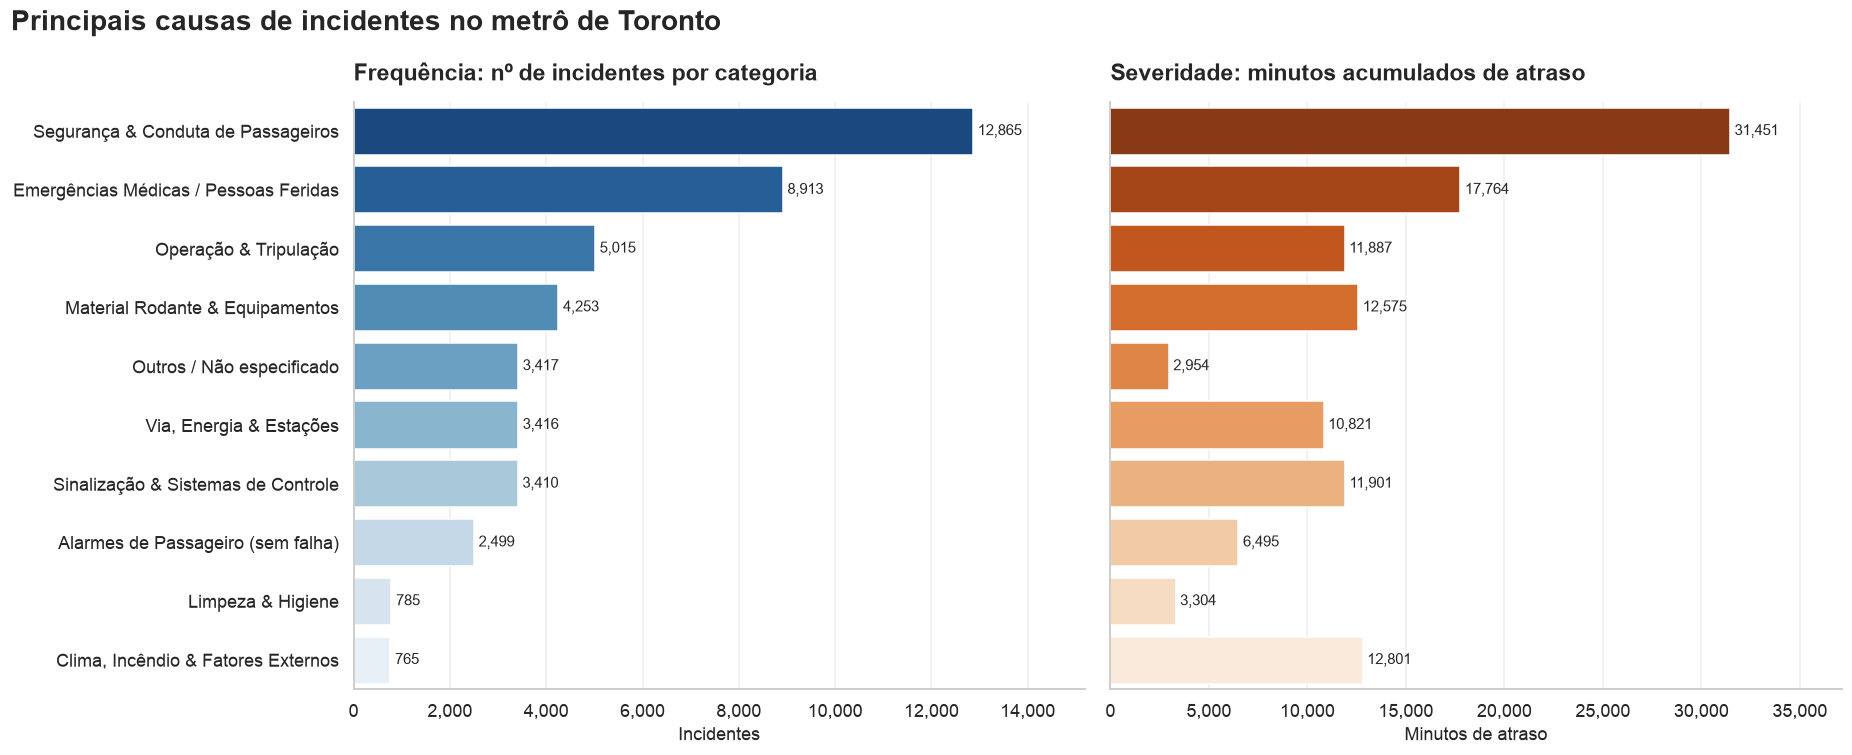

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
order = category_summary.index

sns.barplot(x=category_summary["Incidentes"], y=order, hue=order, palette="Blues_r", legend=False, ax=axes[0])
label_bars(axes[0])
format_thousands(axes[0])
style_axis(axes[0], "Frequência: nº de incidentes por categoria", "Incidentes")

minutes = category_summary["Minutos_Atraso"]
sns.barplot(x=minutes, y=order, hue=order, palette="Oranges_r", legend=False, ax=axes[1])
label_bars(axes[1])
format_thousands(axes[1])
style_axis(axes[1], "Severidade: minutos acumulados de atraso", "Minutos de atraso")

for ax in axes:
    ax.margins(x=0.18)
fig.suptitle("Principais causas de incidentes no metrô de Toronto", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

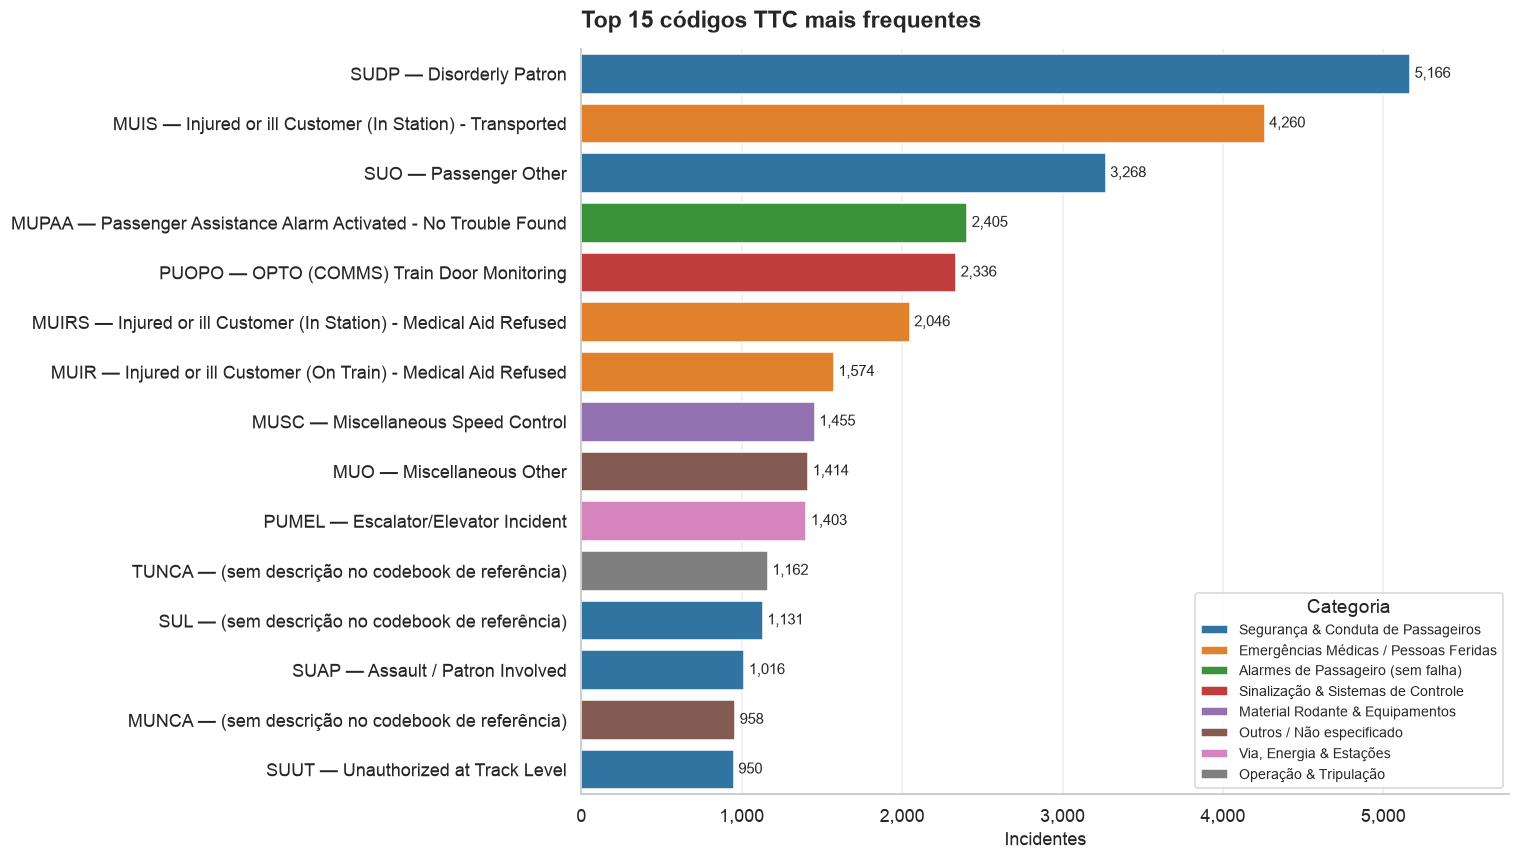

In [43]:
fig, ax = plt.subplots(figsize=(14, 8))
labels = [f"{code} — {desc if len(desc) <= 58 else desc[:57] + '…'}" for code, desc, _ in top_codes.index]
sns.barplot(x=top_codes["Incidentes"].values, y=labels, hue=top_codes.index.get_level_values("Incident_Category"),
            dodge=False, palette="tab10", ax=ax)
label_bars(ax)
format_thousands(ax)
ax.margins(x=0.12)
ax.legend(title="Categoria", loc="lower right", fontsize=9)
style_axis(ax, "Top 15 códigos TTC mais frequentes", "Incidentes")
plt.tight_layout()
plt.show()

> ### 📊 Interpretação — Principais causas
>
> Os dois painéis lado a lado mostram a diferença entre **frequência** e **severidade**: *Segurança & Conduta* lidera em
> ambos, mas *Clima, Incêndio & Externos* — quase invisível no painel de frequência — salta para o **3º lugar em minutos**.
> *Emergências Médicas* faz o caminho inverso: muito frequente, impacto moderado. No ranking de códigos, o top 3
> (`SUDP`, `MUIS`, `SUO`) é inteiramente ligado a passageiros; o primeiro código técnico relevante é `PUOPO`
> (monitoramento de portas na operação com um só operador, *OPTO*).

### 5.2 Padrões temporais

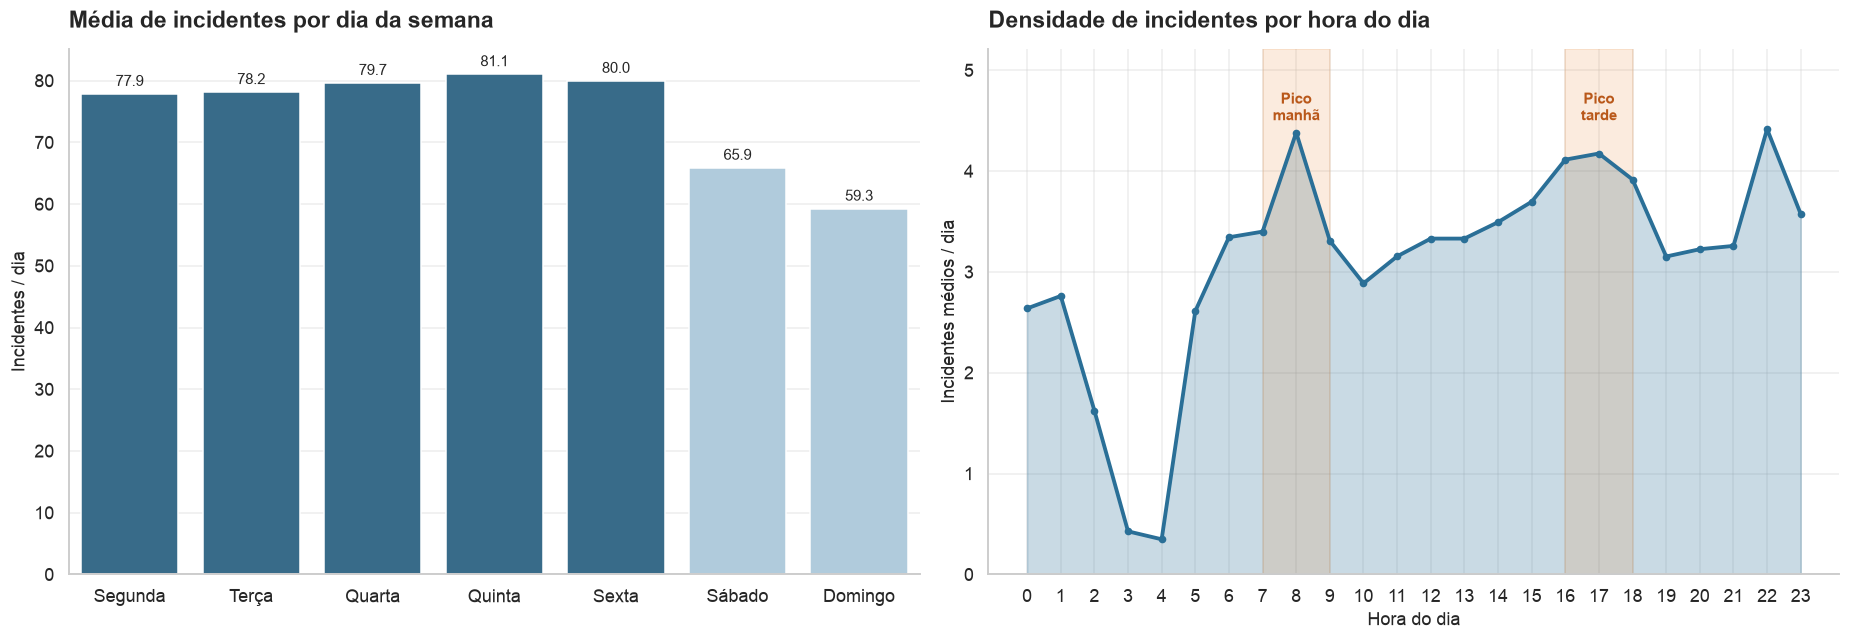

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

day_labels = weekday_summary.index.astype(str).tolist()
day_colors = ["#2A6F97"] * 5 + ["#A9CCE3"] * 2
sns.barplot(x=day_labels, y=weekday_summary["Incidentes_por_Dia"].values, hue=day_labels,
            palette=day_colors, legend=False, dodge=False, ax=axes[0])
label_bars(axes[0], fmt="{:.1f}")
style_axis(axes[0], "Média de incidentes por dia da semana", "", "Incidentes / dia")

hourly = hourly_summary["Incidentes"] / df["Date"].nunique()
axes[1].fill_between(hourly.index, hourly.values, color="#2A6F97", alpha=0.25)
axes[1].plot(hourly.index, hourly.values, color="#2A6F97", lw=2.5, marker="o", markersize=4)
for start, end in RUSH_HOUR_WINDOWS:
    axes[1].axvspan(start.hour, end.hour, color="#E67E22", alpha=0.15)
axes[1].text(8, hourly.max() * 1.02, "Pico\nmanhã", ha="center", color="#B9581A", fontsize=10, fontweight="bold")
axes[1].text(17, hourly.max() * 1.02, "Pico\ntarde", ha="center", color="#B9581A", fontsize=10, fontweight="bold")
axes[1].set_xticks(range(24))
axes[1].set_ylim(0, hourly.max() * 1.18)
style_axis(axes[1], "Densidade de incidentes por hora do dia", "Hora do dia", "Incidentes médios / dia")

plt.tight_layout()
plt.show()

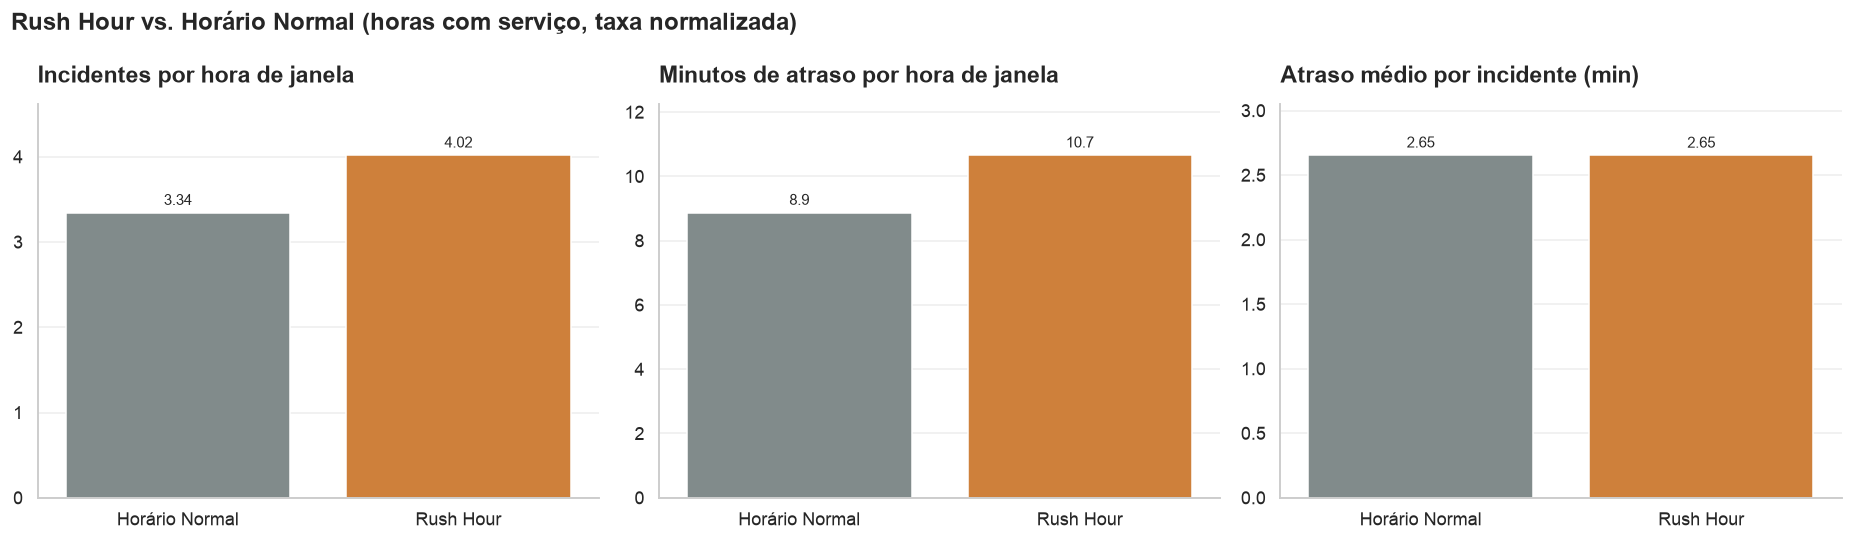

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
rush_colors = {"Rush Hour": "#E67E22", "Horário Normal": "#7F8C8D"}
metrics = [
    ("Incidentes_por_Hora", "Incidentes por hora de janela", "{:.2f}"),
    ("Minutos_por_Hora", "Minutos de atraso por hora de janela", "{:.1f}"),
    ("Atraso_Medio", "Atraso médio por incidente (min)", "{:.2f}"),
]
for ax, (column, title, fmt) in zip(axes, metrics):
    sns.barplot(x=rush_summary.index, y=rush_summary[column], hue=rush_summary.index, palette=rush_colors,
                legend=False, ax=ax)
    label_bars(ax, fmt=fmt)
    ax.margins(y=0.15)
    style_axis(ax, title)
fig.suptitle("Rush Hour vs. Horário Normal (horas com serviço, taxa normalizada)", fontsize=16, fontweight="bold",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

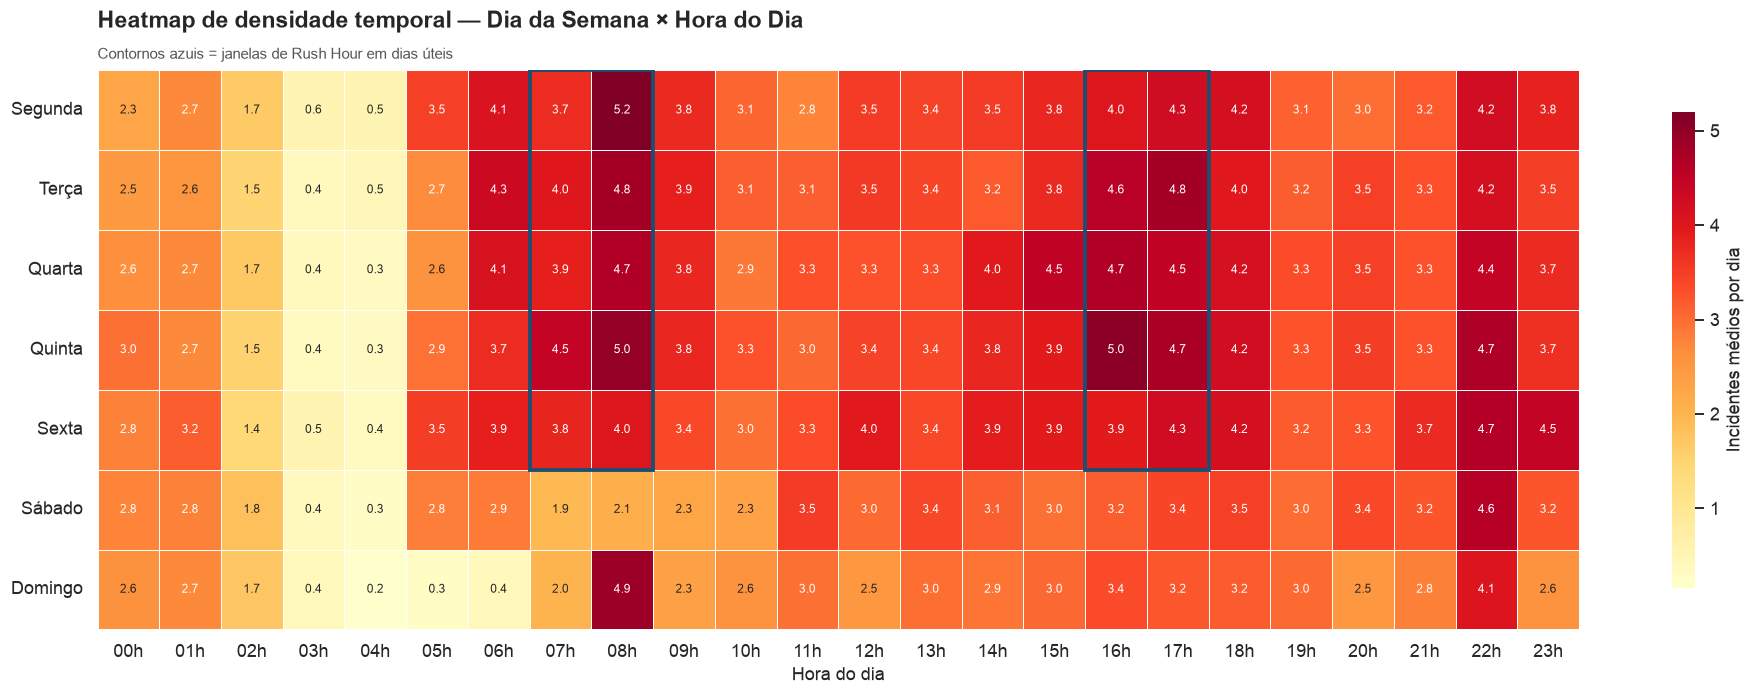

In [46]:
fig, ax = plt.subplots(figsize=(18, 6.5))
sns.heatmap(weekday_hour_matrix, cmap="YlOrRd", linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Incidentes médios por dia", "shrink": 0.85}, annot=True, fmt=".1f",
            annot_kws={"fontsize": 8}, ax=ax)
for start, end in RUSH_HOUR_WINDOWS:
    ax.add_patch(plt.Rectangle((start.hour, 0), end.hour - start.hour, 5, fill=False, edgecolor="#1B4F72", lw=2.5))
ax.set_xticklabels([f"{h:02d}h" for h in range(24)], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
style_axis(ax, "Heatmap de densidade temporal — Dia da Semana × Hora do Dia", "Hora do dia", "",
           subtitle="Contornos azuis = janelas de Rush Hour em dias úteis")
plt.tight_layout()
plt.show()

> ### 📊 Interpretação — Padrões temporais
>
> - O gráfico semanal confirma o **padrão de demanda**: dias úteis estáveis em ~78–81 incidentes/dia, queda no sábado e
>   ainda maior no domingo.
> - A curva horária mostra a **madrugada quase zerada** (03–04h, sem serviço), a subida brusca na abertura (05–06h) e os
>   picos de manhã e tarde destacados em laranja.
> - O comparativo Rush × Normal evidencia que **o pico eleva a taxa de incidentes e de minutos por hora em ~20%**, com
>   atraso médio por incidente igual.
> - No **heatmap**, as células mais quentes estão nas janelas de pico dos dias úteis (contornos azuis) —
>   **segunda às 08h** é a combinação mais crítica — e na faixa das 22h todos os dias. O fim de semana tem uma manhã
>   visivelmente "fria", e o domingo só "acende" às 08h.
>
> **Implicação prática:** reforço de equipes de resposta (segurança, primeiros socorros, manutenção de prontidão) deve
> seguir o mapa de calor: picos de dias úteis e janela de abertura do serviço.

### 5.3 Atraso acumulado por linha do metrô

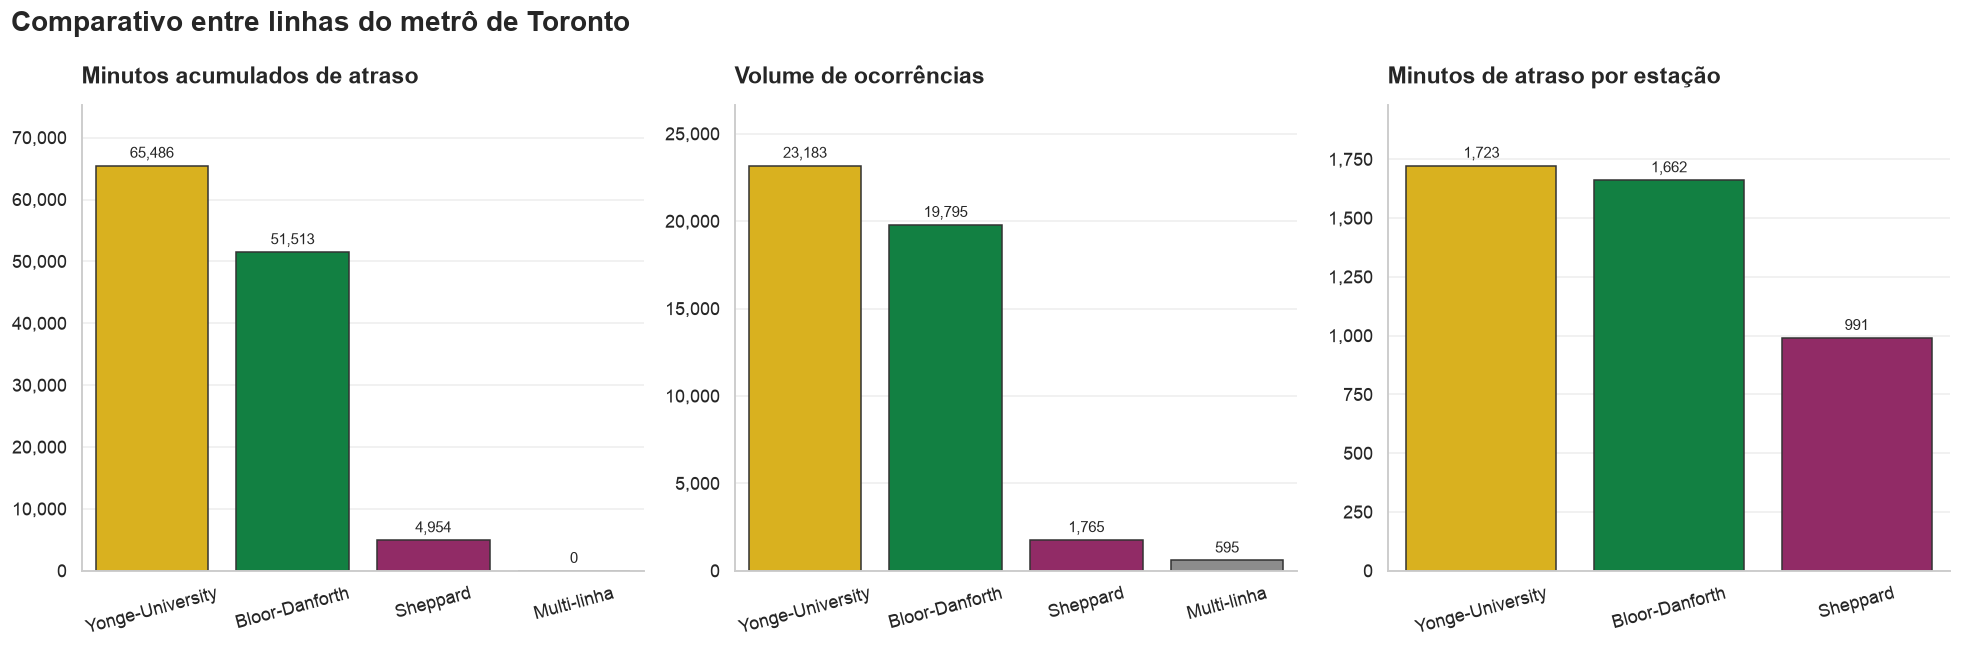

In [47]:
lines_order = line_summary.index
colors = [LINE_COLORS[name] for name in lines_order]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
panels = [
    ("Minutos_Atraso", "Minutos acumulados de atraso", "{:,.0f}"),
    ("Incidentes", "Volume de ocorrências", "{:,.0f}"),
    ("Minutos_por_Estacao", "Minutos de atraso por estação", "{:,.0f}"),
]
for ax, (column, title, fmt) in zip(axes, panels):
    data = line_summary[column].dropna()
    sns.barplot(x=data.index, y=data.values, hue=data.index, palette=[LINE_COLORS[n] for n in data.index],
                legend=False, edgecolor="#333333", ax=ax)
    label_bars(ax, fmt=fmt)
    format_thousands(ax, "y")
    ax.margins(y=0.15)
    ax.tick_params(axis="x", rotation=15)
    style_axis(ax, title)
fig.suptitle("Comparativo entre linhas do metrô de Toronto", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

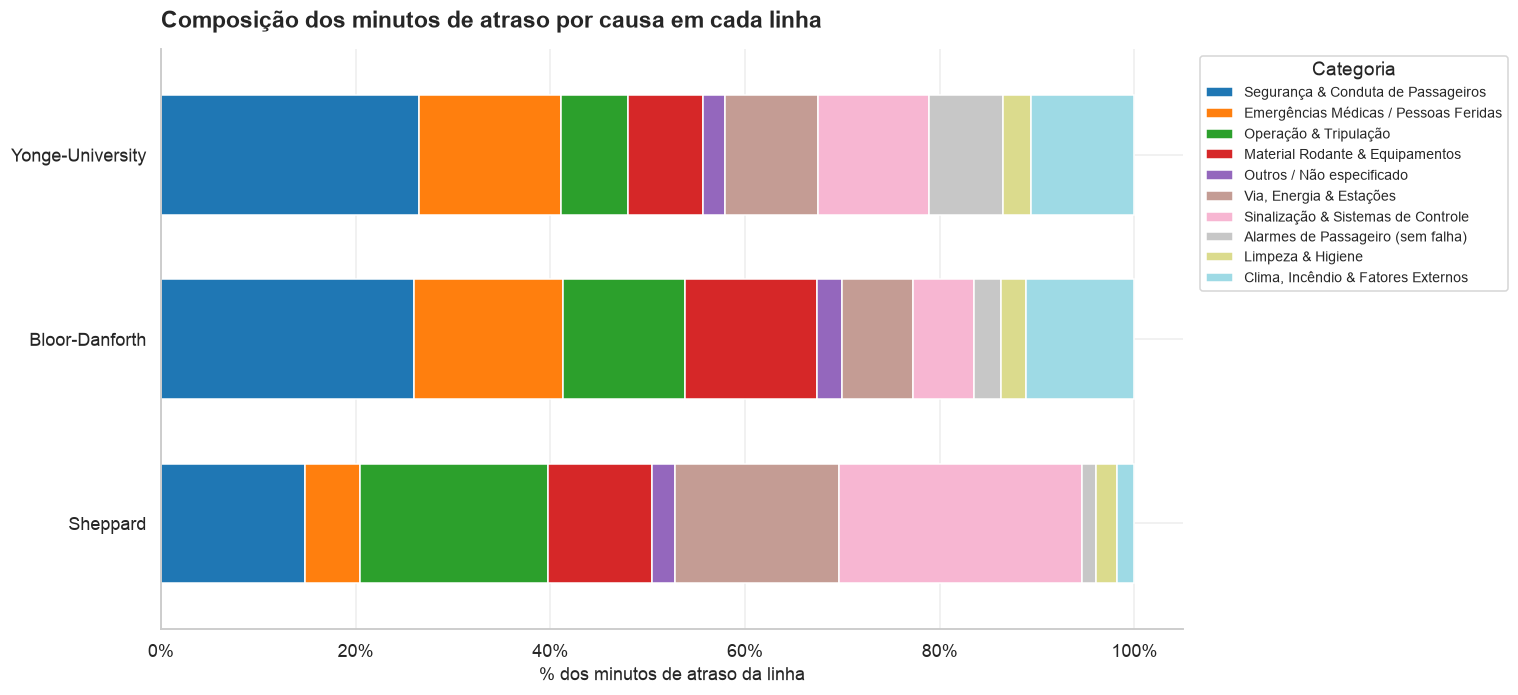

In [48]:
fig, ax = plt.subplots(figsize=(14, 6.5))
share_plot = line_category_share.T.loc[["Yonge-University", "Bloor-Danforth", "Sheppard"]]
share_plot = share_plot[category_summary.index.intersection(share_plot.columns)]
share_plot.plot(kind="barh", stacked=True, colormap="tab20", width=0.65, ax=ax, edgecolor="white")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(title="Categoria", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.invert_yaxis()
style_axis(ax, "Composição dos minutos de atraso por causa em cada linha", "% dos minutos de atraso da linha")
plt.tight_layout()
plt.show()

> ### 📊 Interpretação — Linhas
>
> Em números absolutos, **Yonge-University** é a linha que mais sofre, mas o terceiro painel (minutos por estação) mostra
> que **YU e BD estão no mesmo patamar** quando ajustadas pelo tamanho. O gráfico de composição revela que a solução não
> é única: YU e BD precisam de ações sobre **comportamento e segurança de passageiros**, enquanto a **Sheppard** precisa de
> atenção a **sinalização e operação** — exatamente as categorias que dominam seus minutos de atraso.

### 5.4 Top 10 estações mais impactadas

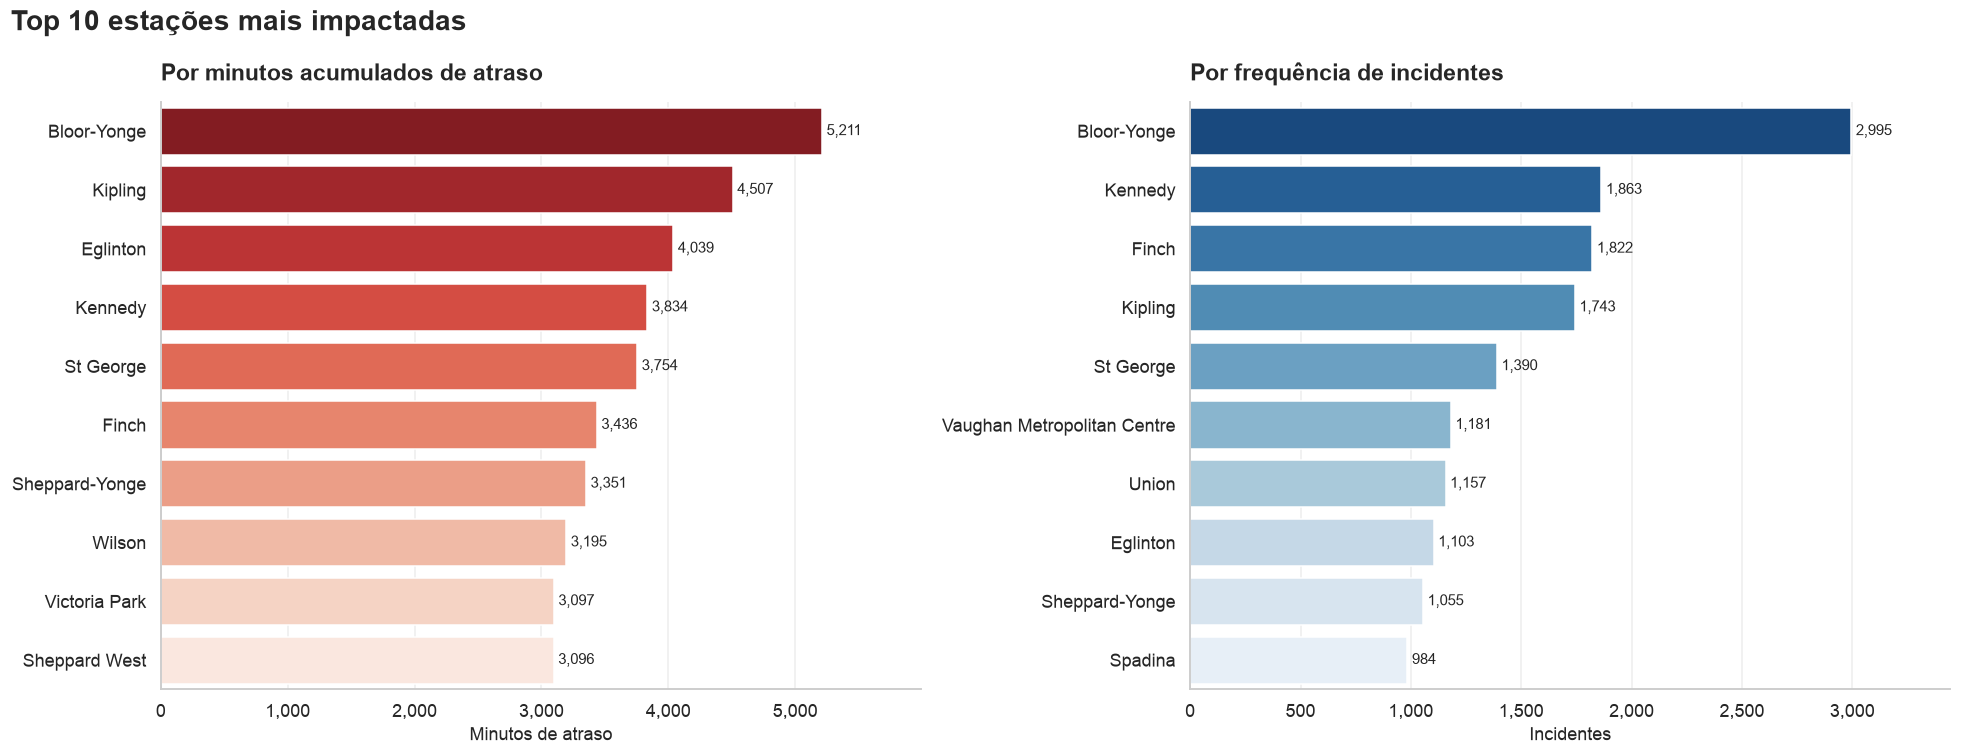

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

def title_case(names):
    return [name.title().replace("'S", "'s").replace("Tmu", "TMU") for name in names]

sns.barplot(x=top10_by_minutes["Minutos_Atraso"], y=title_case(top10_by_minutes.index),
            hue=title_case(top10_by_minutes.index), palette="Reds_r", legend=False, ax=axes[0])
label_bars(axes[0])
format_thousands(axes[0])
axes[0].margins(x=0.15)
style_axis(axes[0], "Por minutos acumulados de atraso", "Minutos de atraso")

sns.barplot(x=top10_by_frequency["Incidentes"], y=title_case(top10_by_frequency.index),
            hue=title_case(top10_by_frequency.index), palette="Blues_r", legend=False, ax=axes[1])
label_bars(axes[1])
format_thousands(axes[1])
axes[1].margins(x=0.15)
style_axis(axes[1], "Por frequência de incidentes", "Incidentes")

fig.suptitle("Top 10 estações mais impactadas", fontsize=18, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

> ### 📊 Interpretação — Top 10 estações
>
> **Bloor-Yonge** está isolada no topo dos dois rankings. A comparação entre os painéis separa dois perfis:
>
> - **Estações de alto volume e baixo atraso médio** (Bloor-Yonge, Finch, Vaughan MC, Union): muitos incidentes rápidos,
>   tipicamente conduta de passageiros e emergências médicas;
> - **Estações de volume moderado e alto atraso médio** (Eglinton, Sheppard West, Victoria Park, Wilson): menos ocorrências,
>   porém mais longas — alvo prioritário de investigação técnica.
>
> **Implicação prática:** priorizar Bloor-Yonge, Kipling, Kennedy, Finch e St George concentra o esforço onde frequência
> e minutos se sobrepõem.

### 5.5 Impacto no passageiro por categoria

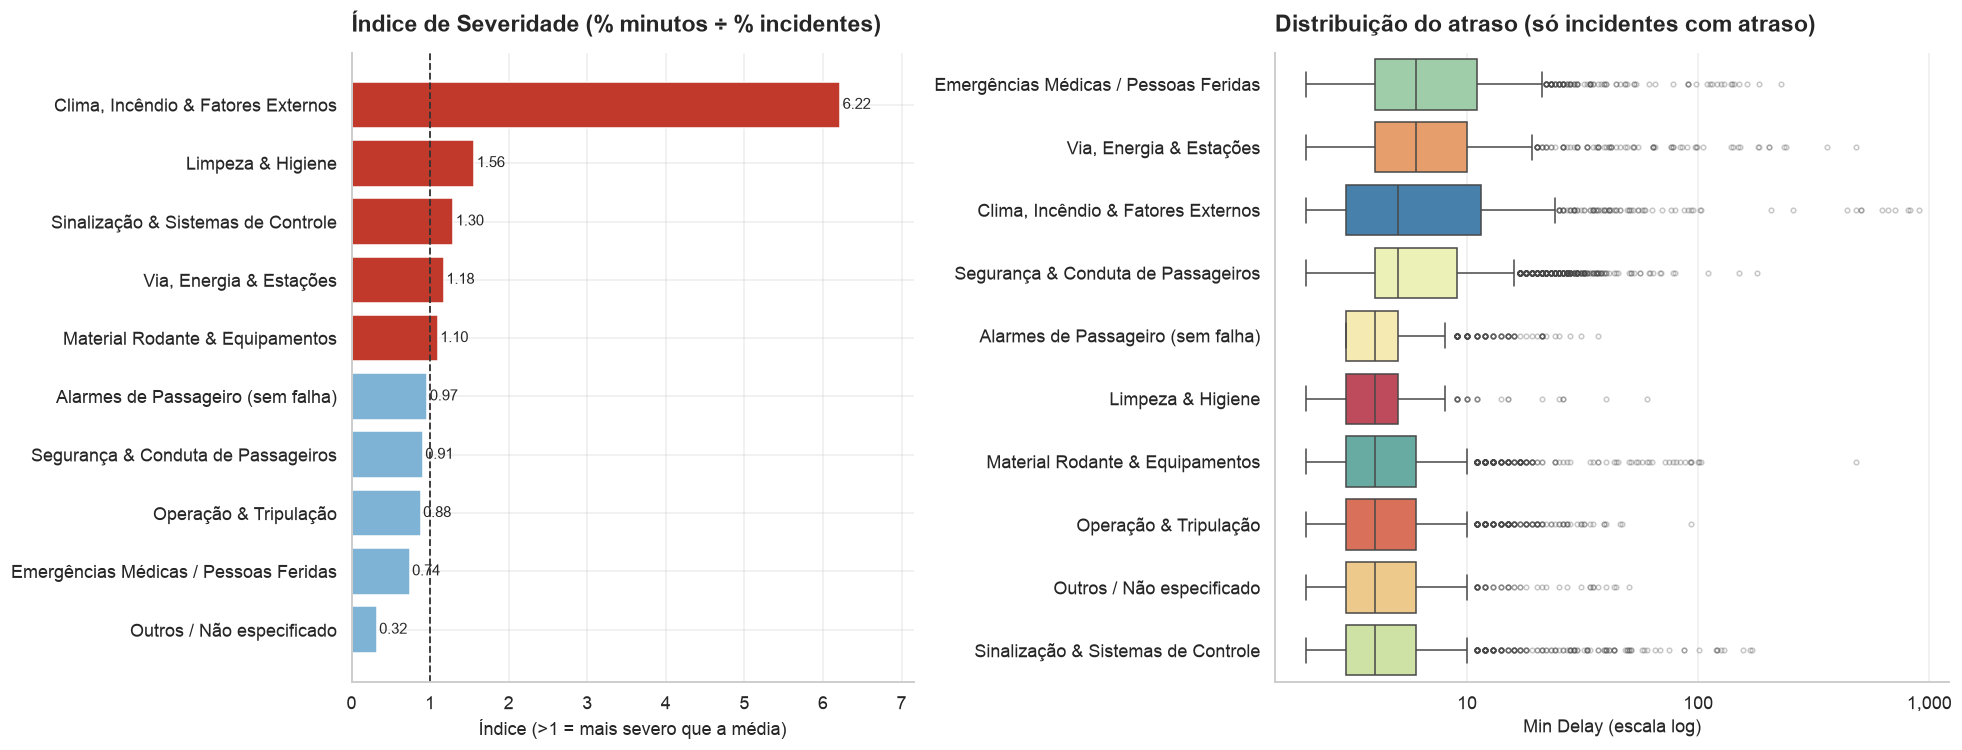

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.2]})

severity = category_impact.sort_values("Indice_Severidade")
bar_colors = ["#C0392B" if v > 1 else "#7FB3D5" for v in severity["Indice_Severidade"]]
axes[0].barh(severity.index, severity["Indice_Severidade"], color=bar_colors)
axes[0].axvline(1, color="#333333", ls="--", lw=1.2)
for y, value in enumerate(severity["Indice_Severidade"]):
    axes[0].text(value + 0.03, y, f"{value:.2f}", va="center", fontsize=10)
axes[0].margins(x=0.15)
style_axis(axes[0], "Índice de Severidade (% minutos ÷ % incidentes)", "Índice (>1 = mais severo que a média)")

delayed = df[df["Has_Delay"]]
order_box = delayed.groupby("Incident_Category")["Min Delay"].median().sort_values(ascending=False).index
sns.boxplot(data=delayed, y="Incident_Category", x="Min Delay", order=order_box, hue="Incident_Category",
            palette="Spectral", legend=False, ax=axes[1], flierprops={"marker": ".", "alpha": 0.3})
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
style_axis(axes[1], "Distribuição do atraso (só incidentes com atraso)", "Min Delay (escala log)", "")

plt.tight_layout()
plt.show()

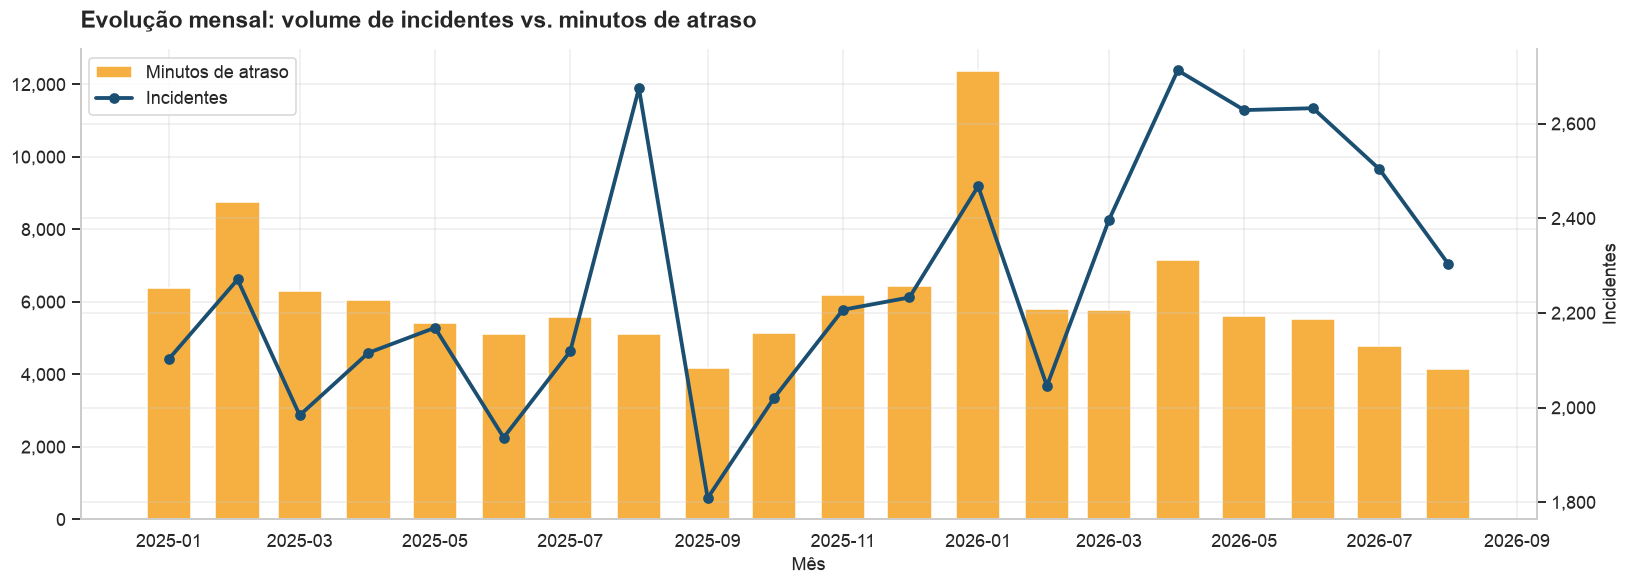

In [51]:
fig, ax = plt.subplots(figsize=(15, 5.5))
monthly = df.groupby("Year_Month").agg(Incidentes=("Code", "size"), Minutos=("Min Delay", "sum"))
monthly.index = monthly.index.to_timestamp()

ax.bar(monthly.index, monthly["Minutos"], width=20, color="#F5B041", label="Minutos de atraso")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["Incidentes"], color="#1B4F72", marker="o", lw=2.5, label="Incidentes")
ax2.spines["right"].set_visible(True)
format_thousands(ax, "y")
format_thousands(ax2, "y")
ax.set_ylabel("Minutos de atraso")
ax2.set_ylabel("Incidentes")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, ["Minutos de atraso", "Incidentes"], loc="upper left")
style_axis(ax, "Evolução mensal: volume de incidentes vs. minutos de atraso", "Mês")
plt.tight_layout()
plt.show()

> ### 📊 Interpretação — Impacto no passageiro
>
> - O **Índice de Severidade** separa com clareza as categorias "caras" (vermelho, > 1) das "baratas" (azul, < 1).
>   Clima, Incêndio & Externos está muito à frente; categorias técnicas e de limpeza vêm em seguida.
> - O **boxplot em escala log** mostra que, entre incidentes que de fato atrasam o serviço, a mediana fica entre 4 e 6
>   minutos em todas as categorias — a diferença de impacto vem da **cauda**: clima e infraestrutura têm caudas
>   que chegam a centenas de minutos.
> - A **série mensal** mostra que o volume de incidentes é relativamente estável (~1,8 a 2,7 mil/mês; média de ~2,1 mil em 2025
>   e ~2,5 mil em 2026), enquanto os minutos têm picos isolados em **fevereiro/2025** e, principalmente, **janeiro/2026**
>   (~12 mil minutos, o dobro de um mês típico) — ambos associados a tempestades de inverno.
>
> **Implicação prática:** planos de contingência de inverno (degelo de trilhos, trens de tempestade, reforço de
> manutenção da via) têm o maior retorno por evento evitado.

---
## 6. Conclusões e respostas às perguntas de pesquisa

In [52]:
key_numbers = {
    "Período analisado": f"{df['Date'].min():%d/%m/%Y} a {df['Date'].max():%d/%m/%Y}",
    "Incidentes analisados": f"{len(df):,}",
    "Minutos totais de atraso": f"{df['Min Delay'].sum():,.0f}",
    "% de incidentes que atrasam o serviço": pct(df["Has_Delay"].mean()),
    "Categoria mais frequente": f"{category_summary.index[0]} ({pct(category_summary['Pct_Incidentes'].iloc[0])})",
    "Categoria com mais minutos": f"{category_impact.index[0]} ({pct(category_impact['Pct_Minutos'].iloc[0])})",
    "Linha com mais minutos": f"{line_summary.index[0]} ({line_summary['Minutos_Atraso'].iloc[0]:,.0f} min)",
    "Estação mais frequente": f"{top10_by_frequency.index[0].title()} ({top10_by_frequency['Incidentes'].iloc[0]:,})",
    "Estação com mais minutos": f"{top10_by_minutes.index[0].title()} ({top10_by_minutes['Minutos_Atraso'].iloc[0]:,.0f} min)",
    "Min Delay médio por ocorrência": f"{df['Min Delay'].mean():.2f} min",
    "Min Gap médio por ocorrência": f"{df['Min Gap'].mean():.2f} min",
    "Aumento da taxa de incidentes no pico": f"{rush_lift:+.1%}",
}
pd.Series(key_numbers, name="Valor").to_frame()

,Valor
Período analisado,01/01/2025 a 31/08/2026
Incidentes analisados,"45,338"
Minutos totais de atraso,"121,953"
% de incidentes que atrasam o serviço,34.8%
Categoria mais frequente,Segurança & Conduta de Passageiros (28.4%)
Categoria com mais minutos,Segurança & Conduta de Passageiros (25.8%)
Linha com mais minutos,"Yonge-University (65,486 min)"
Estação mais frequente,"Bloor-Yonge (2,995)"
Estação com mais minutos,"Bloor-Yonge (5,211 min)"
Min Delay médio por ocorrência,2.69 min


### Respostas às perguntas de pesquisa

**1. Volume de ocorrências e principais motivos**
A principal causa de incidentes é **Segurança & Conduta de Passageiros** (~28% dos incidentes), seguida de
**Emergências Médicas** (~20%) e **Operação & Tripulação** (~11%). Causas técnicas (Material Rodante, Sinalização,
Via/Energia) respondem juntas por ~25%. O código individual mais frequente é `SUDP` (passageiro desordeiro).

**2. Padrões temporais**
Dias úteis concentram ~27% mais incidentes por dia que o fim de semana, com quinta-feira no topo. O **Rush Hour é mais
vulnerável em frequência** (+20% de incidentes por hora; +26% só em dias úteis), mas não em severidade (atraso médio
igual). O heatmap aponta **segunda às 08h** como a combinação mais crítica, além das janelas de pico dos dias úteis e da
faixa das 22h (dominada por registros administrativos).

**3. Linhas e estações**
**Yonge-University** acumula mais minutos (~65 mil) e mais ocorrências (~23 mil); ajustada pelo número de estações,
empata com Bloor-Danforth. **Bloor-Yonge** é a estação mais crítica em frequência e em minutos; o top 10 é dominado por
terminais (Kipling, Kennedy, Finch, Vaughan MC) e estações de integração (St George, Sheppard-Yonge, Spadina).

**4. Impacto no passageiro**
Por ocorrência: **~2,7 min de atraso médio** e **~3,7 min de intervalo médio entre trens**. Considerando só os incidentes
que atrasam o serviço (~35%): ~7,7 min de atraso e ~10,7 min de intervalo. Em minutos acumulados, lidera
**Segurança & Conduta** (~31 mil min), mas a categoria mais severa por ocorrência é **Clima, Incêndio & Fatores Externos**
(1,7% dos incidentes → 10,5% dos minutos).

### Recomendações

1. **Segurança e acolhimento nas plataformas** de Bloor-Yonge, St George, Union e Eglinton nos picos de dias úteis.
2. **Equipes médicas de prontidão** nos terminais (Finch, Kennedy, Vaughan MC), onde emergências médicas lideram.
3. **Protocolo de abertura do serviço** (checagem de portas/OPTO, liberação de zonas de obra, escala de tripulação).
4. **Plano de contingência de inverno**: o retorno por evento evitado é o maior de todas as categorias.
5. **Foco técnico na Sheppard** (sinalização e operação), cujo perfil de falhas difere das outras linhas.

### Limitações

- `Station` e `Line` são texto livre; cerca de 5% dos registros não puderam ser atribuídos a uma estação (trechos,
  pátios, linha inteira) e ficam fora do ranking de estações.
- ~25% dos registros foram categorizados por *fallback* de prefixo, incluindo códigos recentes sem descrição no
  codebook de referência (`TUNCA`, `SUL`, `MUNCA`, `MUINF`).
- `Min Delay` mede o atraso **no serviço**, não o número de passageiros afetados; um minuto em Bloor-Yonge às 08h afeta
  muito mais gente do que um minuto na Sheppard às 23h. Cruzar com dados de demanda (embarques por estação/hora) é o
  próximo passo natural.
- A análise é descritiva. Um passo seguinte de mineração preditiva seria modelar a probabilidade de um incidente gerar
  atraso (classificação) ou a duração do atraso (regressão), usando as features criadas na etapa 3.